# **🛩️ ATAS**

The **ATAS** (Airial Threat Assesment System) is an end-to-end machine learning engineering project that combines
- computer vision,
- structured machine learning,
- tactical scenario generation,
- and interactive visualization into a single pipeline.

**The project is divided into three major components:**
- Aircraft Classification Model
- ETA Regressor Model
- Hit Classification Model
---

#### **In this notebook**

# **Aircraft Classification Model**

This notebook focuses on building the **Aircraft Classification Model** using `TensorFlow` and `transfer learning techniques` to classify military aircraft into  `101` different categories.

## **1. Problem Definition**

Given an image of a military aircraft, can a deep learning computer vision model (multi-class classification neural network) correctly classify the aircraft into its respective category?

---

## **2. Dataset**

The dataset used in this project contains military aircraft images across 101 aircraft categories and is being taken from [Military Aircraft Detection Dataset on Kaggle](https://www.kaggle.com/datasets/a2015003713/militaryaircraftdetectiondataset/data).

The dataset includes:
- fighter jets,
- bombers,
- helicopters,
- transport aircraft,
- UAVs,
- and reconnaissance aircraft.

Images contain variations in:
- aircraft angles,
- lighting conditions,
- backgrounds,
- scales,
- and image quality.

For this notebook, the `crop/` portion of the dataset will be used since it already contains aircraft images organized by class labels, making it suitable for multi-class image classification tasks.

The dataset was originally designed for fine-grained military aircraft recognition, where some visually similar aircraft variants are grouped into the same class due to minimal external differences.

<details>
<summary>View all 101 aircraft classes</summary>

`A10, A400M, AG600, AH64, AKINCI, AV8B, An124, An22, An225, An72, B1, B2, B21, B52, Be200, C1, C130, C17, C2, C390, C5, CH47, CH53, CL415, E2, E7, EF2000, EMB314, F117, F14, F15, F16, F18, F2, F22, F35, F4, FCK1, H6, Il76, J10, J20, J35, J36, J50, JAS39, JF17, JH7, KAAN, KC135, KF21, KIZILELMA, KJ600, Ka27, Ka52, MQ20, MQ25, MQ28, MQ9, Mi24, Mi26, Mi28, Mi8, Mig29, Mig31, Mirage2000, NH90, P3, RQ4, Rafale, SR71, Su24, Su25, Su34, Su47, Su57, T50, TB001, TB2, Tejas, Tornado, Tu160, Tu22M, Tu95, U2, UH60, US2, V22, V280, Vulcan, WZ10, WZ7, WZ9, X29, X32, XB70, XQ58, Y20, YF23, Z10, Z19`

</details>

---

## **3. Evaluation**

The goal is to correctly classify a military aircraft image into one of 101 categories.

The model will be considered performing well if it achieves **above 80% classification accuracy** on the validation set.

Additional indicators we will track:
- training & validation loss curves (to detect overfitting),
- confusion matrix (to see which aircraft classes the model confuses with each other),
- per-class prediction confidence,
- and visual inspection of sample predictions.

---

## **4. Features**

Some information about the data:

* We are dealing with images (unstructured data) so we will be using deep learning / transfer learning.
* There are `101` categories of military aircraft (101 different classes).
* The `crop/` folder contains `41,441` total cropped aircraft images organized by class label.
* Each class has its own subfolder inside `crop/` — the folder name is the label.
* The `labels_with_split.csv` file contains bounding box annotations and a predefined split column:
  - ~31k training annotations
  - ~7.5k validation annotations
  - ~2.7k test annotations

* Note: This CSV was designed for object detection. For our classifier we use the `crop/` folder directly, but will use the `split` column to respect the original train/validation/test separation.
* Images vary in angle, lighting, background, and scale — making this a fine-grained classification problem.
* Some visually similar aircraft variants are grouped into the same class due to minimal external differences.

## **5. Preparing the Tools**

We will be using the following libraries for this project:
- **NumPy** — numerical operations
- **Pandas** — data manipulation and loading labels
- **Matplotlib** — visualizing images and training curves
- **TensorFlow / Keras** — building and training the deep learning model
- **Scikit-learn** — creating train/validation/test splits and evaluation metrics
- **OS / Pathlib** — navigating file paths and loading images from disk

In [ ]:
import os
import logging

# ── Silence TF C++ backend ───────────────────────────────────────────────────
# TF's core is written in C++ and logs a lot of setup noise by default.
# Level 3 = show ERROR only. (0=all, 1=info, 2=warning, 3=error)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# ── Silence oneDNN ───────────────────────────────────────────────────────────
# oneDNN is Intel's deep learning kernel library — TF uses it internally.
# Disabling its logs stops messages like "oneDNN custom operations are on"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

# ── Silence gRPC + glog ──────────────────────────────────────────────────────
# gRPC is TF's internal communication layer (used even in single-machine training).
# glog is Google's C++ logging library underneath it.
os.environ["GRPC_VERBOSITY"] = "ERROR"
os.environ["GLOG_minloglevel"] = "3"

import tensorflow as tf

# ── Silence TF Python-level logger ───────────────────────────────────────────
# Some warnings surface through TF's Python API rather than the C++ backend.
# These two lines catch those — both point to the same logger, belt-and-suspenders.
tf.get_logger().setLevel("ERROR")
logging.getLogger("tensorflow").setLevel(logging.ERROR)

In [2]:
import datetime, pytz
ist = pytz.timezone("Asia/Kolkata")
datetime.datetime.now(ist).strftime('%Y-%m-%d_%H-%M-%S')

'2026-05-16_23-38-07'

In [3]:
# Importing the required tools

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras # type: ignore

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("Keras Version:", keras.__version__)

# Able to see all the columns
pd.set_option('display.max_columns', None)

TensorFlow Version: 2.16.1
NumPy Version: 1.26.4
Pandas Version: 3.0.2
Keras Version: 3.14.0


## **6. Load Images**

We will load images from the `crop/` folder of the dataset.
Each subfolder inside `crop/` represents one aircraft class and contains cropped images of that aircraft.

Steps:
1. Define the path to the `crop/` folder ✅
2. Count total images and classes ✅
3. Load image file paths and their corresponding class labels ✅
4. Verify the data loaded correctly ✅

### **Environment & Path Configuration**

This section configures project paths and automatically detects whether the notebook is running **locally** or in **Google Colab**.

In [ ]:
import glob
from pathlib import Path
import os

# Set to "auto" (recommended), "colab", or "local"
FORCE_ENV = "auto"

def detect_env():
    in_colab = "COLAB_GPU" in os.environ or os.path.exists("/content")
    return "colab" if in_colab else "local"

ENV = detect_env() if FORCE_ENV == "auto" else FORCE_ENV

if ENV == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/ATAS_Project")
    DATA_ROOT = PROJECT_ROOT / "data"
    LOG_DIR = PROJECT_ROOT / "logs"
    MODEL_DIR = PROJECT_ROOT / "models"
    RELEASE_MODELS_DIR = PROJECT_ROOT / "release_models"
else:
    PROJECT_ROOT = Path("..")
    DATA_ROOT = PROJECT_ROOT / "data"
    LOG_DIR = PROJECT_ROOT / "logs"
    MODEL_DIR = PROJECT_ROOT / "models"
    RELEASE_MODELS_DIR = PROJECT_ROOT / "release_models"

CROP_DIR = DATA_ROOT / "crop"

print("ENV:", ENV)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_ROOT:", DATA_ROOT)
print("CROP_DIR:", CROP_DIR)
print("LOG_DIR:", LOG_DIR)
print("MODEL_DIR:", MODEL_DIR)
print("RELEASE_MODELS_DIR:", RELEASE_MODELS_DIR)
print("CROP_DIR exists:", CROP_DIR.exists())
print("Classes found:", len(glob.glob(str(CROP_DIR / "*"))))

ENV: local
PROJECT_ROOT: ..
DATA_ROOT: ../data
CROP_DIR: ../data/crop
LOG_DIR: ../logs
MODEL_DIR: ../models
RELEASE_MODELS_DIR: ../release_models
CROP_DIR exists: True
Classes found: 101


In [5]:
import os
from pathlib import Path

CROP_DIR = DATA_ROOT / "crop"

class_folders = sorted(os.listdir(CROP_DIR))
total_images = sum(len(os.listdir(CROP_DIR / cls)) for cls in class_folders)

print(f"Total classes: {len(class_folders)}")
print(f"Total images: {total_images}")

Total classes: 101
Total images: 41441


In [6]:
# Checking out labels csv

labels_with_split = pd.read_csv(DATA_ROOT / "labels_with_split.csv")
print(labels_with_split.shape)
print(labels_with_split.head())

(41441, 9)
                           filename  width  height class  xmin  ymin  xmax  \
0  0000e97ea2d086d6759b19b288a8a72c   4928    3264  Mi28  1380  1904  1522   
1  0000e97ea2d086d6759b19b288a8a72c   4928    3264  Mi28  1809  1625  1958   
2  0000e97ea2d086d6759b19b288a8a72c   4928    3264  Mi28  2400  1571  2532   
3  0000e97ea2d086d6759b19b288a8a72c   4928    3264  Mi28  3935  1772  4100   
4  00010041af654d0b8e1e16c824fa9867   1360    2048  UH60   835   526  1233   

   ymax  split  
0  2014  train  
1  1759  train  
2  1727  train  
3  1891  train  
4   741  train  


In [7]:
labels_with_split

,filename,width,height,class,xmin,ymin,xmax,ymax,split
0,0000e97ea2d086d6759b19b288a8a72c,4928,3264,Mi28,1380,1904,1522,2014,train
1,0000e97ea2d086d6759b19b288a8a72c,4928,3264,Mi28,1809,1625,1958,1759,train
2,0000e97ea2d086d6759b19b288a8a72c,4928,3264,Mi28,2400,1571,2532,1727,train
3,0000e97ea2d086d6759b19b288a8a72c,4928,3264,Mi28,3935,1772,4100,1891,train
4,00010041af654d0b8e1e16c824fa9867,1360,2048,UH60,835,526,1233,741,train
...,...,...,...,...,...,...,...,...,...
41436,fff4d4af52e64d95bdafa29f77a81c97,817,479,Mi28,0,119,756,301,test
41437,fffb908c9824dc0da884c43cfe0312b8,6720,4480,EF2000,514,1302,6447,3206,test
41438,fffb908c9824dc0da884c43cfe0312b8,6720,4480,EF2000,0,1746,2698,3061,test
41439,fffd70f851b78035454c0a9367820ca3,1500,1000,B2,240,55,988,944,test


In [8]:
labels_with_split.describe()

,width,height,xmin,ymin,xmax,ymax
count,41441.000000,41441.000000,41441.000000,41441.000000,41441.000000,41441.000000
mean,2056.475133,1399.343307,715.019087,507.202191,1325.372144,805.921817
std,1276.872710,830.675656,798.662180,465.634793,953.931200,573.969376
min,112.000000,119.000000,0.000000,0.000000,22.000000,9.000000
25%,1080.000000,768.000000,142.000000,185.000000,668.000000,411.000000
50%,1600.000000,1170.000000,449.000000,366.000000,1041.000000,639.000000
75%,2830.000000,1879.000000,981.000000,685.000000,1712.000000,1034.000000
max,8508.000000,7360.000000,7895.000000,4919.000000,8256.000000,6720.000000


In [9]:
# Checking wheather there any null values
labels_with_split.info()

<class 'pandas.DataFrame'>
RangeIndex: 41441 entries, 0 to 41440
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filename  41441 non-null  str  
 1   width     41441 non-null  int64
 2   height    41441 non-null  int64
 3   class     41441 non-null  str  
 4   xmin      41441 non-null  int64
 5   ymin      41441 non-null  int64
 6   xmax      41441 non-null  int64
 7   ymax      41441 non-null  int64
 8   split     41441 non-null  str  
dtypes: int64(6), str(3)
memory usage: 2.8 MB


**From info given above:**
- `filename`, `class`, `split` --> are of `str` datatype
- `width`, `height`, `xmin`, `ymin`, `xmax`, `ymax` --> are of `int` data types 

In [10]:
# Counting number of classes in the labels file
labels_with_split["class"].value_counts()

class
F16     2061
F18     1796
C130    1590
F35     1569
F15     1564
        ... 
J50       46
V280      39
WZ10      32
WZ9       15
MQ20      11
Name: count, Length: 101, dtype: int64

**Class distribution is very unbalanced:**

Example:
- **F16** has `2,061` crops
- **MQ20** has only `11`

That's a big gap. Some aircraft are rare in the dataset, some are very common. This will matter later when we train, but we'll handle it when we get there.

In [11]:
# Checking the split division of the dataset
labels_with_split["split"].value_counts()

split
train         31127
validation     7545
test           2769
Name: count, dtype: int64

**We use the CSV to build full file paths for each image.
Each row will have: filepath, label, and split.**

In [12]:
# Peek inside one class folder to see how filenames are structred

sample_class = os.listdir(CROP_DIR)[0]
print("Class: ", sample_class)

sample_files = os.listdir(CROP_DIR/ sample_class)[:5]
print("Files: ", sample_files)

Class:  A10
Files:  ['00c09f406d31a0cd9402862fbd26d930_0.jpg', '00d4b7ea93ca1417393007c61c519f88_0.jpg', '01169f9ba735dfcb46dab62bc5649de9_0.jpg', '016fd73cdece1b76562ec526ba9390ff_0.jpg', '01ed4d81c5d733cbaa266b6ea7821254_0.jpg']


**It confirmed two things:**

- The class folder name **(A10)** is the label
- The files inside are the cropped images we'll use

That's it. That's all we needed to see.

---

### **Building the File Path Dataframe**
Scan all class folders in `crop/` and build a clean dataframe with filepath and label columns.

**We write code that does this:**

- Go through every class folder in crop/
- For every image inside, record the full path and the folder name as the label
- End up with a clean dataframe of filepath + label

In [13]:
# Data Collection
# Scan all the folders and build filepath + label list

records = []

for class_folder in CROP_DIR.iterdir():
    if class_folder.is_dir():
        for image_path in class_folder.glob("*.jpg"):
            records.append({
                "filepath" : str(image_path),
                "label" : class_folder.name
            })            
# records

In [14]:
# Convert to a dataframe
image_df = pd.DataFrame(records)
print(image_df.shape)
print(image_df.head())

(41441, 2)
                                            filepath label
0  ../data/crop/A10/00c09f406d31a0cd9402862fbd26d...   A10
1  ../data/crop/A10/00d4b7ea93ca1417393007c61c519...   A10
2  ../data/crop/A10/01169f9ba735dfcb46dab62bc5649...   A10
3  ../data/crop/A10/016fd73cdece1b76562ec526ba939...   A10
4  ../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...   A10


In [15]:
image_df.head()

,filepath,label
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10


In [16]:
labels_with_split.shape, image_df.shape

# Both having same number of rows

((41441, 9), (41441, 2))

#### **Merging: Add Split Information**

#### **What We Have So Far**

Our `image_df` dataframe:
- **41,441 rows** ✅ (matches the CSV exactly)
- **2 columns:** `filepath`, `label`
- Labels extracted from folder names ✅

#### **What We Need**

Add the `split` column from `label_with_split.csv` so we know which images are for:
- **Training** (75%)
- **Validation** (18%)
- **Testing** (7%)

#### **The Challenge: Joining Two Tables**

Both dataframes have the same 41,441 images, but they identify them differently:

| Source | File ID Format | Example |
|--------|----------------|---------|
| `image_df` | Full filepath | `../data/crop/A10/00c09f406d31a0cd9_0.jpg` |
| `label_with_split` | Filename only | `00c09f406d31a0cd9` |

**We need to extract the filename from the filepath and use it as the merge key.**

In [17]:
# Get first filename from CSV for Mi28
mi28_csv = labels_with_split[labels_with_split["class"] == "Mi28"]["filename"].iloc[0]
print("CSV filename for Mi28: ", mi28_csv)

# Get the first file from Mi28 crop folder
mi28_crop = os.listdir(CROP_DIR/ "Mi28")[:5]
print("Crop filename: ", mi28_crop)

CSV filename for Mi28:  0000e97ea2d086d6759b19b288a8a72c
Crop filename:  ['0000e97ea2d086d6759b19b288a8a72c_0.jpg', '0000e97ea2d086d6759b19b288a8a72c_1.jpg', '0000e97ea2d086d6759b19b288a8a72c_2.jpg', '0000e97ea2d086d6759b19b288a8a72c_3.jpg', '04dbc4ca7d87fb38b22b415bc7c280c0_0.jpg']


### **Adding Split Column to image_df**

We need to match each image filepath to its train/val/test split from the CSV.

The crop filenames look like: `0000e97e_0.jpg`  
The CSV filenames look like: `0000e97e`

They share the same base name. So we:
1. Extract the base filename from the filepath (strip `_0.jpg`) ✅
2. Match it with the CSV filename to get the split ✅
3. Add split to image_df ✅
4. Drop the temporary matching column ✅

In [18]:
# How it works
x = "../data/crop/A10/00c09f_0.jpg"

path = Path(x)
print(path)

stems = path.stem
print(stems)

split = stems.rsplit("_", 1) # It splits a string from the right side at the last(only 1) underscore only.
print(split)

result = split[0]
print(result)

../data/crop/A10/00c09f_0.jpg
00c09f_0
['00c09f', '0']
00c09f


In [19]:
# 1.) Extract base filenames temporarily for matching
image_df["temp"] = image_df["filepath"].apply(
    lambda x : Path(x).stem.rsplit("_", 1)[0]  # Stem -> Gives the filename without the folder and without the extension.
)

image_df.head()

,filepath,label,temp
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,00c09f406d31a0cd9402862fbd26d930
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,00d4b7ea93ca1417393007c61c519f88
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,01169f9ba735dfcb46dab62bc5649de9
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,016fd73cdece1b76562ec526ba9390ff
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,01ed4d81c5d733cbaa266b6ea7821254


In [20]:
# 2.) Get all the unique file names from labels_with_split along with split tag
split_map = labels_with_split[["filename", "split"]].drop_duplicates() # Drops the dublicate rows
print(split_map.shape)
print(split_map.head())

(23143, 2)
                            filename  split
0   0000e97ea2d086d6759b19b288a8a72c  train
4   00010041af654d0b8e1e16c824fa9867  train
5   000106393cfe2343888c584e65fd2274  train
6   0002f2cc10d90392efc3ad30cbda6490  train
22  00032844ab679240fc03ecd27d29a6aa  train


**Note:** Notice the shape --> 23,143 rows. Down from 41,441.

That's because duplicates are gone. Each original photo now appears only once, with its split. Clean.

**Two columns:**

- filename — the original photo name
- split — train, val, or test

That's our lookup table. Given any filename, we can find its split.

In [21]:
print(image_df.columns.tolist())

['filepath', 'label', 'temp']


In [22]:
image_df.head()

,filepath,label,temp
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,00c09f406d31a0cd9402862fbd26d930
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,00d4b7ea93ca1417393007c61c519f88
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,01169f9ba735dfcb46dab62bc5649de9
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,016fd73cdece1b76562ec526ba9390ff
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,01ed4d81c5d733cbaa266b6ea7821254


In [23]:
len(image_df), len(split_map)

(41441, 23143)

In [24]:
# 3.) Merge Split Information into image_df
image_df = image_df.merge(split_map, left_on="temp", right_on="filename")
image_df.head()

,filepath,label,temp,filename,split
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,00c09f406d31a0cd9402862fbd26d930,00c09f406d31a0cd9402862fbd26d930,train
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,00d4b7ea93ca1417393007c61c519f88,00d4b7ea93ca1417393007c61c519f88,train
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,01169f9ba735dfcb46dab62bc5649de9,01169f9ba735dfcb46dab62bc5649de9,train
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,016fd73cdece1b76562ec526ba9390ff,016fd73cdece1b76562ec526ba9390ff,train
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,01ed4d81c5d733cbaa266b6ea7821254,01ed4d81c5d733cbaa266b6ea7821254,train


### **What happened and why?**

**Why we needed this:**
`image_df` had filepath and label but no split (train/val/test).
The split info was sitting in `labels_with_split` CSV.

**The problem:**
- `image_df` filenames look like: `00c09f406d_0.jpg`
- CSV filenames look like: `00c09f406d`
- They don't look the same so we can't match directly.

**What we did:**

1. Extracted the base filename from filepath into a temporary `temp` column
2. Created `split_map` -> a clean lookup table with just filename and split using `label_with_split`
3. Merged both dataframes by matching `temp` with `filename`

**How merge works:**

It doesn't match by row number, it matches by value.
Like a dictionary lookup, give it a word, it finds the meaning.
Length of both dataframes doesn't matter. **(41441, 23143)** -> (`image_df`, `split_map`)

**Result:**
Each image now has its correct filepath, label, and split.

In [25]:
# 4.) Drop temp and filename columns that are no longer needed
image_df = image_df.drop(columns=["temp", "filename"])

print(image_df.shape)
image_df

(41441, 3)


,filepath,label,split
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,train
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,train
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,train
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,train
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,train
...,...,...,...
41436,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41437,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41438,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41439,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test


In [26]:
# Save image_df to CSV for future use
output_path = DATA_ROOT / "image_with_labels.csv"
image_df.to_csv(output_path, index=False)

print("Saved to: ", output_path)
print("Shape: ", image_df.shape)

Saved to:  ../data/image_with_labels.csv
Shape:  (41441, 3)


### **How image_df Was Built**

![image_df_build_flowchat](../assets/notes/image_df_build_flowchart.png)

**Left side (teal):** Scanned the `crop/` folder directly.
Folder name = label. Got filepath + label for all 41,441 images.

**Right side (purple):** Used `labels_with_split.csv` only for the split column.
Dropped duplicates → 23,143 unique original photos.
Extracted base filename from filepath (stripped `_0.jpg`) into a temp column.

**Merge (amber):** Matched temp column with CSV filename → brought split across.

**Result (green):** Clean dataframe with filepath, label, split.
No bounding boxes. No duplicates. Ready for training.

---

## **7. Exploratory Data Analysis (EDA)**

Before building a model, we need to *see* the data.

Goals for this section:
- Confirm the CSV loaded correctly ✅
- Check class distribution (are some aircraft overrepresented?)
- Visualize sample images from different classes

In [27]:
# Reloading the refined csv
aircraft_labels = pd.read_csv(DATA_ROOT / "image_with_labels.csv")
print(aircraft_labels.shape)
aircraft_labels

(41441, 3)


,filepath,label,split
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,train
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,train
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,train
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,train
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,train
...,...,...,...
41436,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41437,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41438,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41439,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test


In [28]:
# Check class distribution because imbalance can bias the model toward majority classes
df = pd.DataFrame(aircraft_labels["label"].value_counts())  # gives us counts sorted descending
df.T

label,F16,F18,C130,F35,F15,J20,V22,EF2000,C2,J10,Rafale,A10,C17,F4,F22,US2,B1,B52,JAS39,B2,AH64,F14,A400M,Su34,Su24,P3,Mig31,Tornado,Tu22M,E2,H6,Su57,Mirage2000,Tu95,AV8B,Su25,KC135,Tu160,TB2,Vulcan,CL415,C5,Mig29,CH47,F117,Y20,MQ9,Mi24,UH60,U2,Mi8,RQ4,Be200,EMB314,Il76,JH7,AG600,JF17,SR71,Ka52,C1,E7,An124,T50,Mi28,C390,An72,XB70,F2,Tejas,Ka27,WZ7,J35,AKINCI,YF23,Z10,FCK1,Mi26,Z19,KF21,Su47,An22,CH53,An225,KJ600,TB001,J36,X32,KAAN,NH90,X29,XQ58,KIZILELMA,B21,MQ25,MQ28,J50,V280,WZ10,WZ9,MQ20
count,2061,1796,1590,1569,1564,917,916,842,833,824,821,793,749,729,713,667,663,639,626,576,566,554,544,538,534,519,504,493,481,480,479,478,469,466,464,458,453,447,431,415,408,403,402,381,378,373,372,371,370,330,325,310,303,302,299,299,281,274,272,271,254,227,226,223,220,206,199,177,168,165,163,158,156,150,147,146,133,133,131,125,124,117,113,112,107,105,102,97,87,73,69,66,64,63,60,47,46,39,32,15,11


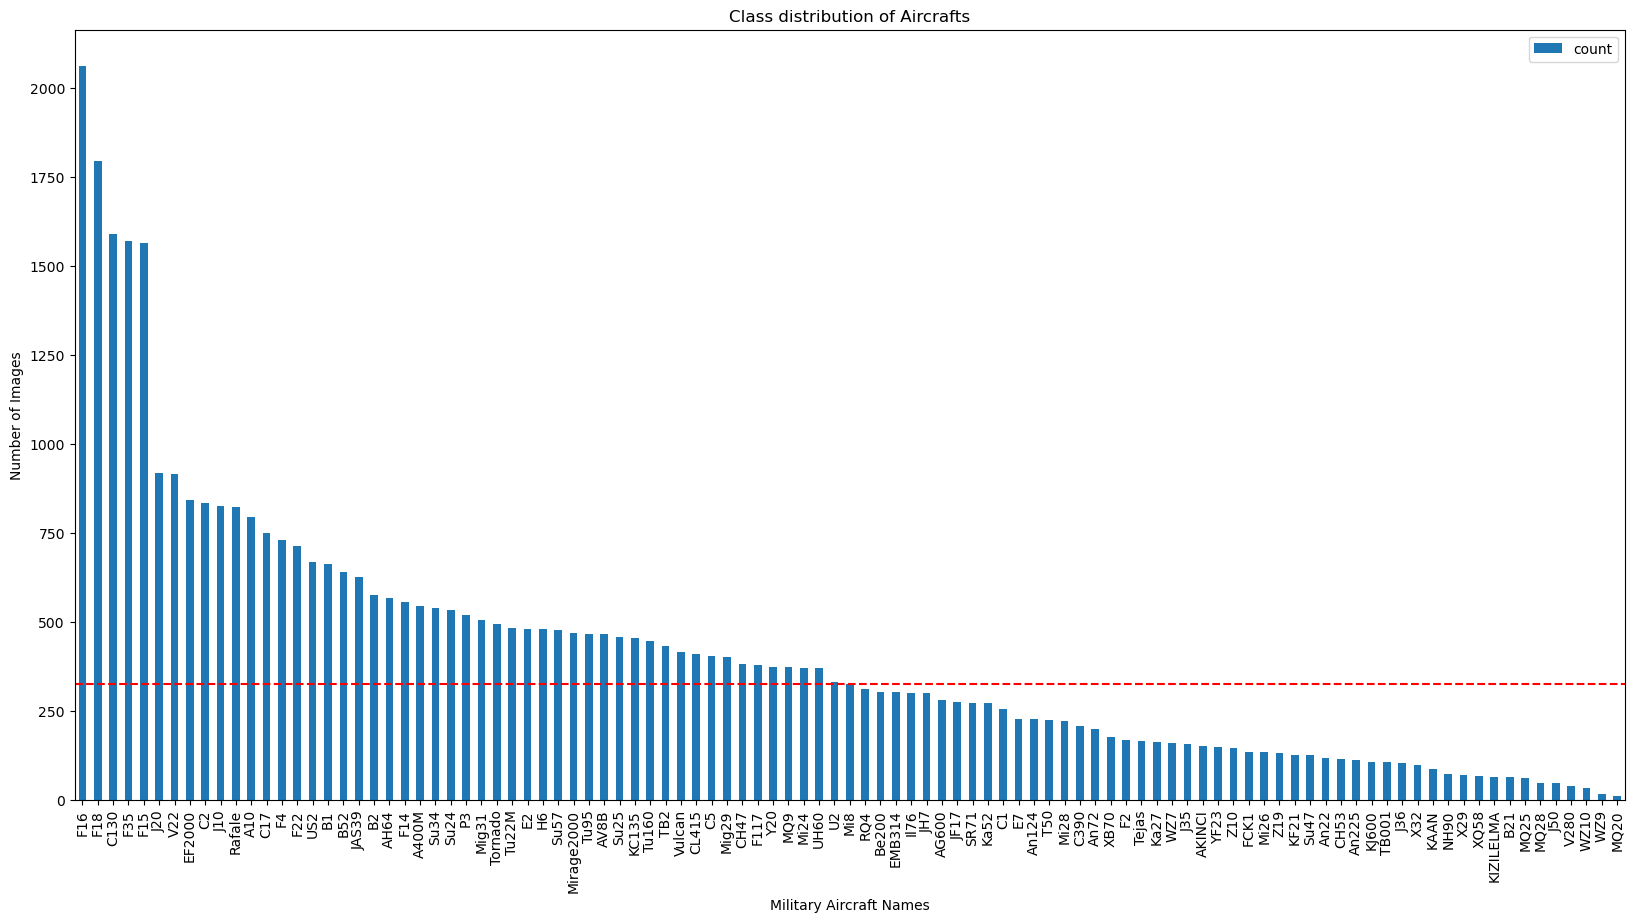

In [29]:
# Visualization of Category distribution of Aircrafts

df.plot.bar(figsize=(20, 10))
plt.title("Class distribution of Aircrafts")
plt.xlabel("Military Aircraft Names")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.axhline(y=np.median(df.values),
           linestyle="--",
           color="red")
plt.show();

# F16 is the dominant class (~2061 images) — the model will naturally lean toward predicting F16 if you don't handle this
# The red median line sits around ~330 images
# Roughly half the classes are below the median — that tail on the right is long
# MQ20 at the far right is nearly invisible (~11 images)

In [30]:
# Top 5 and bottom 5 classes by image count
class_counts = aircraft_labels["label"].value_counts()

top5 = class_counts.head(5)
bottom5 = class_counts.tail(5)

print("Top 5 classes (most images):")
print(top5.to_string())

print("Bottom 5 classes (fewest images):")
print(bottom5.to_string())

Top 5 classes (most images):
label
F16     2061
F18     1796
C130    1590
F35     1569
F15     1564
Bottom 5 classes (fewest images):
label
J50     46
V280    39
WZ10    32
WZ9     15
MQ20    11


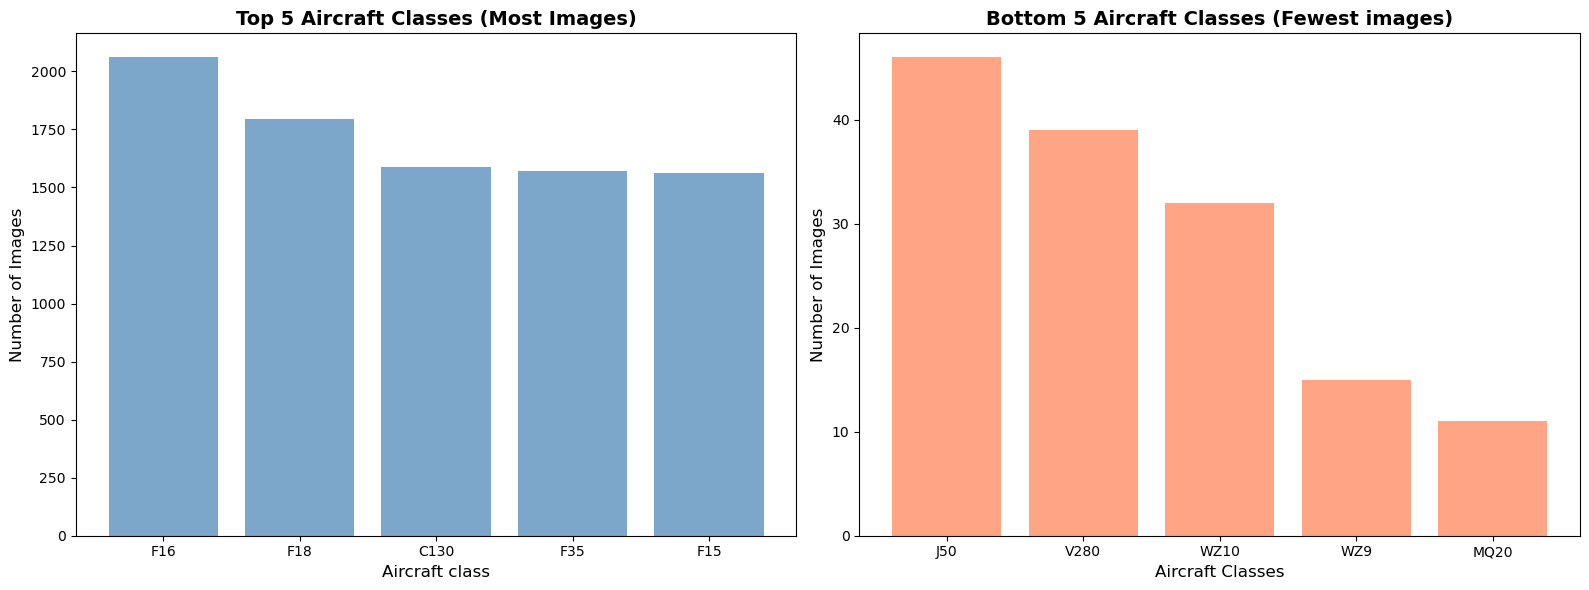

In [31]:
# Visualising the Top 5 and Bottom 5 aircraft classes on the basis of Number of images per class

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,6)) # Give me 1 row, 2 columns of subplots.

# Left subplot: Top 5 most common aircraft
ax1.bar(top5.index,
        top5.values,
        color="steelblue",
        alpha=0.7)   # alpha controls transparency (opacity) of a plotted element: 0.0 = fully transparent, 1.0 = fully opaque.
ax1.set_title("Top 5 Aircraft Classes (Most Images)",
              fontsize=14,
              fontweight="bold")
ax1.set_xlabel("Aircraft class",
               fontsize=12)
ax1.set_ylabel("Number of Images",
               fontsize=12)

# Right subplot: Bottom 5 least common aircraft
ax2.bar(bottom5.index,
        bottom5.values,
        color="coral",
        alpha=0.7)
ax2.set_title("Bottom 5 Aircraft Classes (Fewest images)",
              fontsize=14,
              fontweight="bold")
ax2.set_xlabel("Aircraft Classes",
               fontsize=12)
ax2.set_ylabel("Number of Images",
               fontsize=12)

# Cleanup spacing so labels don't overlap
plt.tight_layout()
plt.show();

In [32]:
aircraft_labels.head()

,filepath,label,split
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,train
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,train
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,train
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,train
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,train


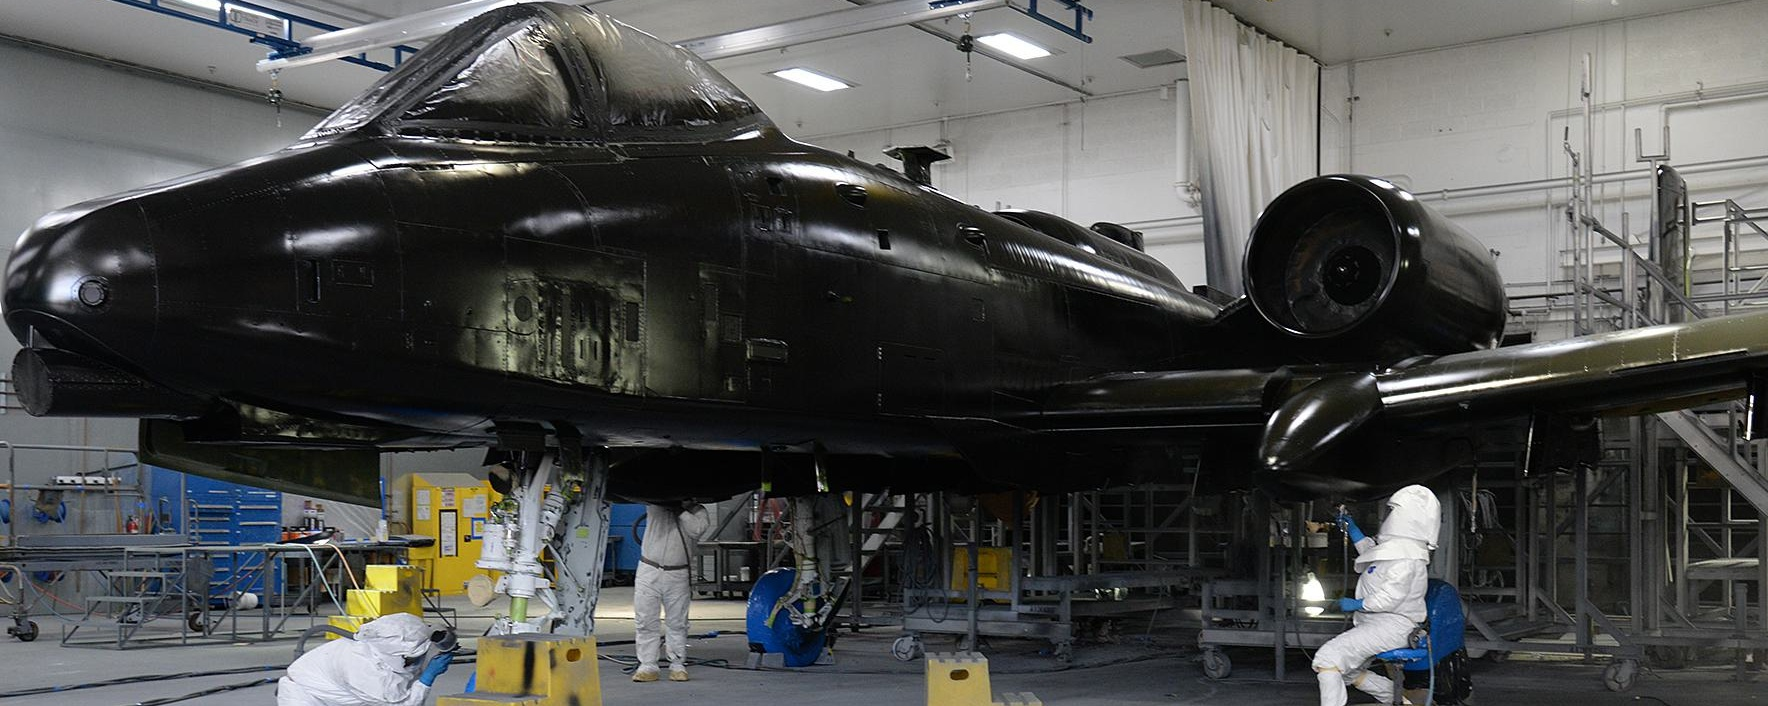

In [33]:
# Let's view an image
from IPython.display import Image
Image(str(aircraft_labels["filepath"][0]))

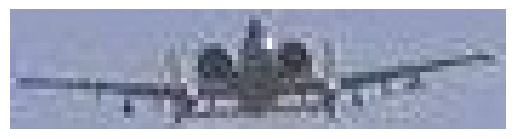

In [34]:
# Another way
# PIL = Python Imaging Library. 
# It loads image files into an object you can
# manipulate (resize, crop, convert color channels etc.) 
# before displaying. Think of it as the "image handler" 
# and matplotlib as the "screen."

from PIL import Image
img = Image.open(aircraft_labels["filepath"][1])
plt.axis("off")
plt.imshow(img);

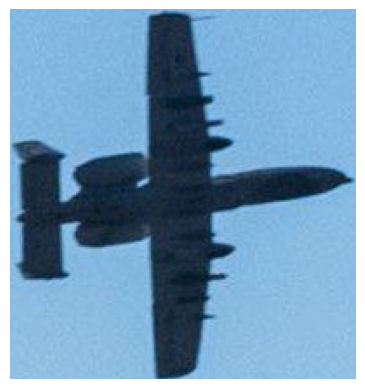

In [35]:
# Another way
img_path = aircraft_labels["filepath"].iloc[2]
img = plt.imread(img_path)
plt.imshow(img)
plt.axis("off")
plt.show();

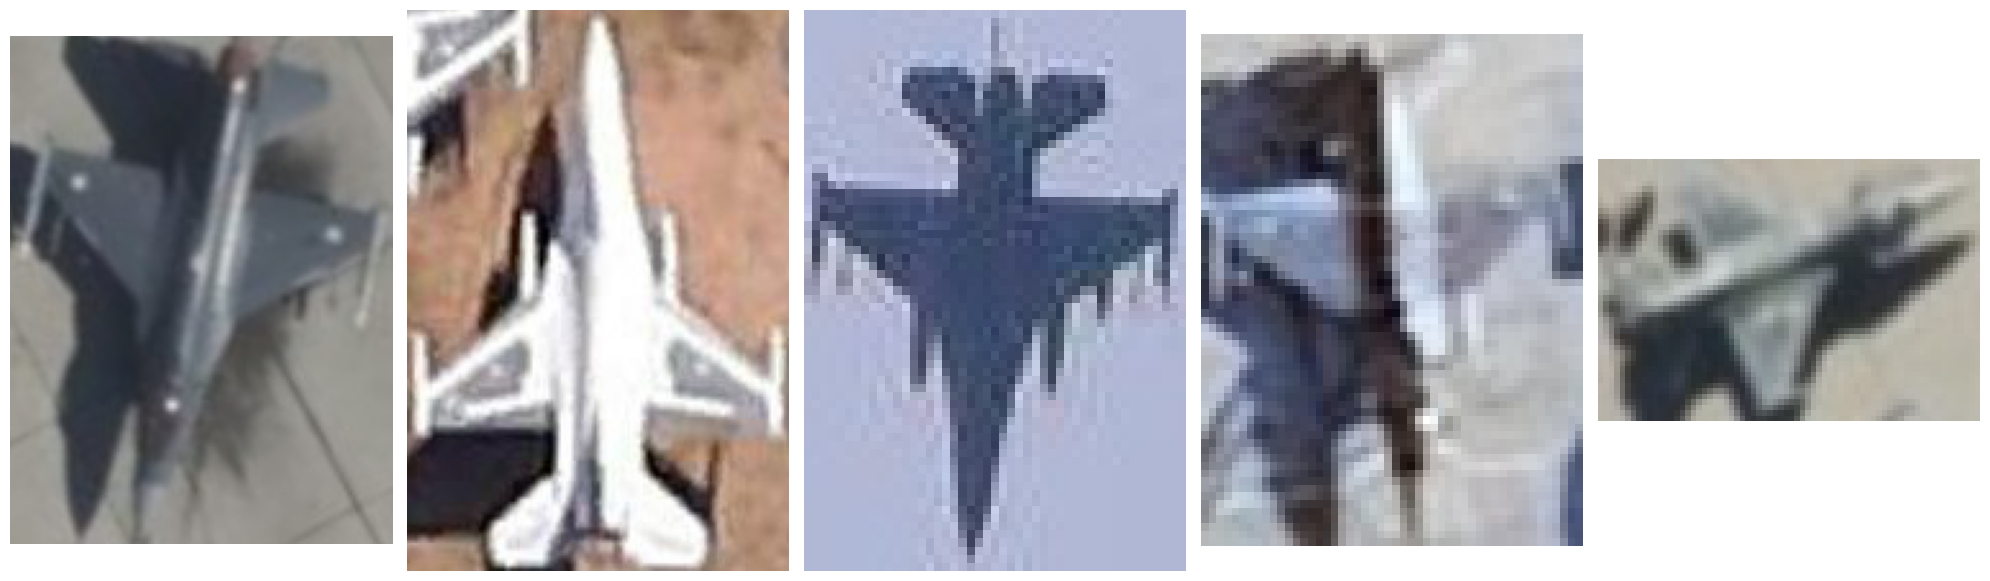

In [36]:
# Showing 5 Random images of F16

# Creating a DataFrame only for F16
f16_df = aircraft_labels[aircraft_labels["label"] == "F16"]
# Taking random 5 paths
random_path_f16 = f16_df["filepath"].sample(n=5, random_state=42).to_list()

# Create 1 row, 5 columns of subplots
fig, axes = plt.subplots(1, 5, figsize=(20, 8))

# Plot image in its own subplot
for ax, path in zip(axes, random_path_f16):
    img = plt.imread(path)
    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()    
plt.show();


# axes[0]  ←→  path_1
# axes[1]  ←→  path_2
# axes[2]  ←→  path_3



In [37]:
# Making function to plot random 5 images of a class

def show_class_images(class_name:str):
    """
    This function takes any class name and shows 5 random images of that Aircraft class
    """
    # Creating a Dataframe for the specific class
    class_df = aircraft_labels[aircraft_labels["label"] == class_name]
    
    # Taking random 5 filepaths of the class as list
    random_image_paths = class_df["filepath"].sample(n=5, random_state=42).to_list()
    
    # Ploting a figure with 1 row and 5 columns
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))  # figsize=(width, height)
    
    # Plot image in its own subplot
    for ax, path in zip(axes, random_image_paths):
        img = plt.imread(path)   # plt.imread(path) reads the image file and returns it as a numpy array of shape (height, width, channels). Channels is usually 3 for RGB.
        ax.imshow(img)
        ax.axis("off")
        ax.set_aspect("auto")   # tells matplotlib to adapts to any image shape
    
    # So that all image look nice and constant
    fig.suptitle(class_name)
    plt.tight_layout()  # It automatically adjusts spacing between subplots so they don't overlap or get cut off — titles, labels, images all stay clean.
    plt.show();

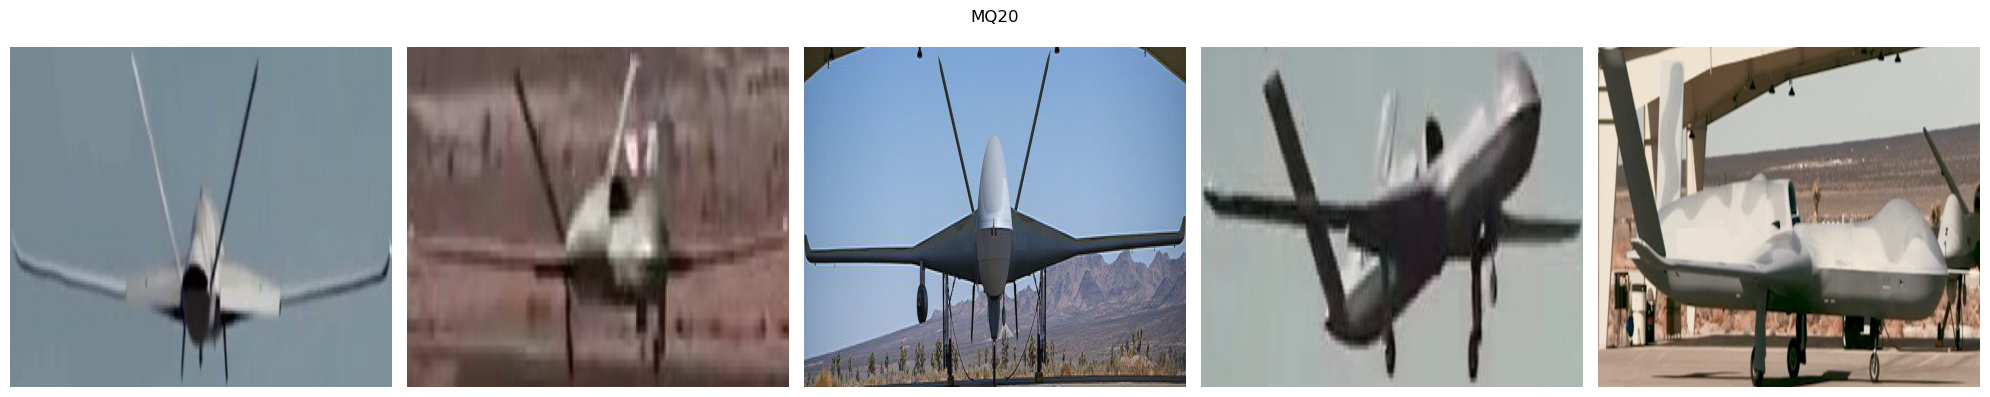

In [38]:
# Show images for aircraft MQ20
show_class_images("MQ20")

(50, 250, 3)


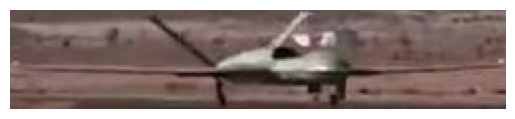

In [39]:
# Checking the actual pixel dimensions for one image Eg. MQ20
mq20_df = aircraft_labels[aircraft_labels["label"] == "MQ20"]

# Taking one image
img = plt.imread(mq20_df["filepath"].iloc[0])  # iloc -> integer index based finder (only the position)

# Dimention of the image
print(img.shape)

# Showing the image
plt.imshow(img)
plt.axis("off")
plt.show();

**(50, 250, 3) means:**

- 50 pixels tall
- 250 pixels wide
- 3 color channels (RGB)

### **Collecting shape of each image in the dataset**

Transfer learning models (like **MobileNetV2** which you'll use) require all images to be the **same fixed size** as input — e.g. `(224, 224, 3)`. So you have to resize everything.

**The question is:** what size should you resize to?

- If your images are mostly 50×250, resizing to 224×224 squashes them badly and loses information
  
- If sizes vary wildly across the dataset, you need to know the range before deciding

This EDA step tells you the reality of your data so you make an informed resize decision not a random one.


**What we are gonna need is:**
- Min height and width
- Max height and width
- Median height and width

In [40]:
# # Collect the shape of every image in the dataset and store the heights and weights seperately

# # Creating a Image path df
# image_path_df = aircraft_labels["filepath"]

# # shape -> (height, width, channels)
# height = []
# width = []

# # Itterating over paths
# for path in image_path_df.values:
#     img = plt.imread(path)  # Converted in NumPy array
#     shape = img.shape
#     height.append(shape[0])
#     width.append(shape[1])
    
# # Create a Shape dataframe
# shape_df = pd.DataFrame({
#     "height" : height,
#     "width" : width,
# })

# shape_df

In [41]:
# # Getting Max, Min and Median values for Height and Width

# # Height
# max_height = np.max(shape_df["height"])
# min_height = np.min(shape_df["height"])
# median_height = np.median(shape_df["height"])

# # Width
# max_width = np.max(shape_df["width"])
# min_width = np.min(shape_df["width"])
# median_width = np.median(shape_df["width"])

# print("Max Height: ", max_height)
# print("Min Height: ", min_height)
# print("Median Height: ", median_height)
# print()
# print("Max Width: ", max_width)
# print("Min Width: ", min_width)
# print("Median Width: ", median_width)

**Looking at these numbers carefully:**

- **Heights** range from `5px` to `4912px`, **median** `174px`
- **Widths** range from `9px` to `8074px`, **median** `364px`
---

### **EDA Insights**

#### **Class Distribution**
- Dataset: 41,441 images across 101 aircraft classes
- Significant class imbalance exists
- **Top 5 classes (most images):** F16 (2061), F18 (1796), C130 (1590), F35 (1569), F15 (1564)
- **Bottom 5 classes (fewest images):** J50 (46), V280 (39), WZ10 (32), WZ9 (15), MQ20 (11)
- Median class size: ~330 images
- Imbalance risk: model may bias toward majority classes (e.g. F16)

#### **Image Size Distribution**
- Heights range from 5px to 4912px — median 174px
- Widths range from 9px to 8074px — median 364px
- Sizes vary wildly across the dataset
- **Resize decision: (224, 224)** — sits above median, standard for transfer learning models like MobileNetV2

#### **Visual Sample Check**
- Verified labels visually using random samples per class
- Images are wide and short in most cases (confirmed via shape check)

In [ ]:
# Image shape constants — derived from 41,441 image analysis
MAX_HEIGHT = 4912
MIN_HEIGHT = 5
MEDIAN_HEIGHT = 174

MAX_WIDTH = 8074
MIN_WIDTH = 9
MEDIAN_WIDTH = 364

# Resize target for transfer learning
IMG_SIZE = (224, 224)

: 

### **Constants**

- Image shape analysis was run once across all 41,441 images. Results hardcoded to avoid recomputation.
  
- Resize target set to (224, 224) - standard for **MobileNetV2** transfer learning.
  
- **EfficientNetB4** considered but requires 4-6GB VRAM at 380×380 input - too tight for a 4GB GPU.

---

## **8. Data Pipeline (Image Loading + Preprocessing)**

The model cannot train on a CSV of filepaths. This section builds the pipeline that:
1. Encodes labels into one-hot vectors (101 classes) ✅
2. Loads images from disk using their filepaths ✅
3. Normalizes pixel values from [0, 255] to [0, 1] ✅ 
4. Resizes all images to (224, 224) for MobileNetV2 ✅
5. Batches and shuffles data using tf.data for efficient training ✅

### **Encoding labels (One-Hot Encoding)**

Each label is a string (e.g. "F16"). The model outputs 101 probabilities — one per class.
To compare against that, each label must become a 101-length boolean array.

Approach:
- Get all 101 unique class names (sorted → consistent order) ✅
- For each image's label, compare against every class ✅
- Where it matches → 1, everywhere else → 0 ✅

In [43]:
aircraft_labels["label"]

0        A10
1        A10
2        A10
3        A10
4        A10
        ... 
41436    Z19
41437    Z19
41438    Z19
41439    Z19
41440    Z19
Name: label, Length: 41441, dtype: str

In [44]:
# Getting all the names of the aircrafts
unique_classes = sorted(np.unique(aircraft_labels["label"]))
unique_classes = np.array(unique_classes)
print(unique_classes.shape)
unique_classes

(101,)


array(['A10', 'A400M', 'AG600', 'AH64', 'AKINCI', 'AV8B', 'An124', 'An22',
       'An225', 'An72', 'B1', 'B2', 'B21', 'B52', 'Be200', 'C1', 'C130',
       'C17', 'C2', 'C390', 'C5', 'CH47', 'CH53', 'CL415', 'E2', 'E7',
       'EF2000', 'EMB314', 'F117', 'F14', 'F15', 'F16', 'F18', 'F2',
       'F22', 'F35', 'F4', 'FCK1', 'H6', 'Il76', 'J10', 'J20', 'J35',
       'J36', 'J50', 'JAS39', 'JF17', 'JH7', 'KAAN', 'KC135', 'KF21',
       'KIZILELMA', 'KJ600', 'Ka27', 'Ka52', 'MQ20', 'MQ25', 'MQ28',
       'MQ9', 'Mi24', 'Mi26', 'Mi28', 'Mi8', 'Mig29', 'Mig31',
       'Mirage2000', 'NH90', 'P3', 'RQ4', 'Rafale', 'SR71', 'Su24',
       'Su25', 'Su34', 'Su47', 'Su57', 'T50', 'TB001', 'TB2', 'Tejas',
       'Tornado', 'Tu160', 'Tu22M', 'Tu95', 'U2', 'UH60', 'US2', 'V22',
       'V280', 'Vulcan', 'WZ10', 'WZ7', 'WZ9', 'X29', 'X32', 'XB70',
       'XQ58', 'Y20', 'YF23', 'Z10', 'Z19'], dtype='<U10')

In [45]:
# Generating boolean label for F16
unique_classes == "F16"

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False])

Right now it's **True/False**. We want **1/0**.

In [46]:
# Generating integer label for F16
(unique_classes == "F16").astype(int)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Let's make a function that convert string label into one-hot encoded array

In [ ]:
# Function to convert a single label string into a one-hot encoded array

def label_to_encoded_array(label:str):
    """
    Convert the label of the aircraft into one-hot encoded array of length of 101, 
    every value in 101 length array reperesent each aircraft
    1 -> True
    0 -> False
    """
    
    encoded_label = (unique_classes == str(label)).astype(int)
    return encoded_label

In [48]:
# Getting encoded labels for Su57
encoded_su57 = label_to_encoded_array("Su57")
encoded_su57

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Since now we have a function to convert our labels into one-hot encoded array let's apply this on our whole dataset

In [49]:
aircraft_labels

,filepath,label,split
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,train
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,train
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,train
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,train
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,train
...,...,...,...
41436,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41437,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41438,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test
41439,../data/crop/Z19/ffb195452d886cd8cd303777eee8a...,Z19,test


In [50]:
aircraft_labels["encoded_label"] = aircraft_labels["label"].map(label_to_encoded_array)
aircraft_labels.head()

,filepath,label,split,encoded_label
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


**Now we have encoded all the labels in to one-hot encoded arrays, which can be understood by our model.**

Now let's load and preprocess our images

### **Loading and Preprocessing Images**

Each image must be:
- Loaded from disk using its filepath
- Decoded into a tensor (RGB)
- Resized to (224, 224) -> MobileNetV2 input requirement
- Normalized from [0, 255] to [0, 1] -> helps the model train faster and more stably

In [51]:
# Method 1
# Open the image
image = plt.imread(aircraft_labels["filepath"][0])
print(image.shape)
print()

# Convert the image into tensor
tensor_image = tf.constant(image)  # Passing numpy array
print(tensor_image.shape)
print(tensor_image.dtype)
print(tensor_image)

(706, 1768, 3)

(706, 1768, 3)
<dtype: 'uint8'>
tf.Tensor(
[[[145 145 147]
  [142 142 144]
  [140 140 142]
  ...
  [123 120 111]
  [125 122 113]
  [126 123 114]]

 [[143 143 145]
  [141 141 143]
  [139 139 141]
  ...
  [126 123 114]
  [125 122 113]
  [125 122 113]]

 [[142 142 144]
  [140 140 142]
  [139 139 141]
  ...
  [127 124 115]
  [126 123 114]
  [126 123 114]]

 ...

 [[143 143 151]
  [143 143 151]
  [144 144 152]
  ...
  [ 59  61  58]
  [ 59  61  58]
  [ 59  61  58]]

 [[145 144 149]
  [144 143 148]
  [143 144 148]
  ...
  [ 56  58  55]
  [ 55  57  54]
  [ 54  56  53]]

 [[145 144 149]
  [144 143 148]
  [142 143 147]
  ...
  [ 54  56  53]
  [ 53  55  52]
  [ 53  55  52]]], shape=(706, 1768, 3), dtype=uint8)


In [52]:
# Method 2
# Read raw bytes from the disk
raw = tf.io.read_file(aircraft_labels["filepath"][0])

# Decode into image tensor (RGB)
image = tf.image.decode_jpeg(raw, channels=3)

print(image.shape)
print(image.dtype)
print(image)

(706, 1768, 3)
<dtype: 'uint8'>
tf.Tensor(
[[[144 144 144]
  [142 142 142]
  [140 140 140]
  ...
  [123 120 111]
  [125 122 113]
  [126 123 114]]

 [[142 142 142]
  [140 140 140]
  [139 139 139]
  ...
  [125 122 113]
  [125 122 113]
  [124 121 112]]

 [[142 142 142]
  [140 140 140]
  [139 139 139]
  ...
  [126 123 114]
  [126 123 114]
  [126 123 114]]

 ...

 [[146 149 156]
  [146 149 154]
  [147 150 157]
  ...
  [ 58  60  55]
  [ 58  60  55]
  [ 58  60  55]]

 [[144 145 150]
  [143 144 148]
  [142 143 148]
  ...
  [ 55  57  54]
  [ 55  57  54]
  [ 54  56  53]]

 [[143 144 148]
  [142 143 147]
  [141 142 146]
  ...
  [ 53  55  52]
  [ 53  55  52]
  [ 52  54  51]]], shape=(706, 1768, 3), dtype=uint8)


#### **Image Loading**
- `tf.io.read_file(filepath)` -- reads raw bytes from disk, stays inside TF
- `tf.image.decode_jpeg(raw, channels=3)` -- decodes bytes into RGB tensor
- Must use TF-native functions (not `plt.imread`) so the pipeline can run efficiently at scale

**Why not plt.imread + tf.constant?**
- plt.imread is a Python operation -- TF cannot include it in an automated pipeline
- tf.constant just wraps existing memory -- it does not read files
- TF-native reading stays on the assembly line -- faster, parallelizable, pipeline-compatible

In [53]:
# Define the image size
# IMG_SIZE = (224, 224) already defined above

# Create a function to preprocess the image
def process_image(image_path:str, image_size=IMG_SIZE):
    """
    Load and preprocess a single image from disk
    - Reads raw bytes from filepath (the image)
    - Decode into RBG tensor
    - Resizes to (224, 224)
    - Normalize pixel values from [0, 225] to [0, 1]
    
    Args:
    filepath: path to the image file (string)
    Returns:
    Preprocessed image tensor of shape (224, 224, 3)
    """
    
    # Read the image as raw vytes from filepath
    image = tf.io.read_file(image_path)
    
    # Decodes into RGB Tensor (Turn the jpg/jpeg image into numerical Tensor with 3 colour channels (Red, Green, Blue))
    image = tf.image.decode_jpeg(image, channels=3)
    
    # Convert the colour channel values from 0-255 to 0-1 values (Normalization of pixels)
    image = tf.image.convert_image_dtype(image, tf.float32)
    
    # Resize the image to desired shape
    image = tf.image.resize(image, image_size)
    
    return image

#### **Image Preprocessing Function** — `process_image()`
- Takes a single filepath string as input
- `tf.io.read_file()` — reads raw bytes from disk
- `tf.image.decode_jpeg(channels=3)` — decodes into RGB tensor
- `tf.image.convert_image_dtype(tf.float32)` — normalizes pixels from [0, 255] to [0, 1] (must run before resize — resize converts to float32 internally, which breaks normalization)
- `tf.image.resize()` — resizes to (224, 224)
- Returns a single tensor of shape (224, 224, 3)

In [54]:
# Test process_image on a single image
test_image = process_image(aircraft_labels["filepath"][0])
print(test_image.shape)
print(test_image.dtype)
print(test_image)
print()
print(test_image.numpy().min(), test_image.numpy().max())

(224, 224, 3)
<dtype: 'float32'>
tf.Tensor(
[[[0.5468488  0.5468488  0.5468488 ]
  [0.5540751  0.5540751  0.5540751 ]
  [0.54901963 0.54901963 0.5568628 ]
  ...
  [0.45229104 0.44052634 0.40523222]
  [0.48862532 0.4768606  0.44156653]
  [0.4891736  0.4774089  0.44211477]]

 [[0.5346855  0.5346855  0.5346855 ]
  [0.54723394 0.54723394 0.54723394]
  [0.55024517 0.55024517 0.5580883 ]
  ...
  [0.49596494 0.48420024 0.44890612]
  [0.49316156 0.48139682 0.4461027 ]
  [0.4989321  0.4871674  0.45187327]]

 [[0.52858806 0.52858806 0.5256118 ]
  [0.53042156 0.53042156 0.5274454 ]
  [0.54509807 0.54509807 0.5529412 ]
  ...
  [0.5206804  0.5104038  0.47064543]
  [0.5015754  0.4912988  0.45154038]
  [0.5058824  0.49411768 0.46179974]]

 ...

 [[0.42608032 0.44299415 0.46300405]
  [0.5068915  0.5426906  0.5752743 ]
  [0.4980177  0.5254687  0.55684125]
  ...
  [0.2508198  0.25474137 0.23399076]
  [0.26840422 0.27232578 0.24879639]
  [0.24084528 0.2604531  0.23692371]]

 [[0.5016363  0.51340103 0.533

- `process_image()` takes a single filepath and returns a preprocessed tensor
- Order matters: normalize before resize —> resize converts to float32 internally
- Output: shape (224, 224, 3), dtype float32, pixel values in [0, 1]

### **Building the tf.data Pipeline**

`tf.data.Dataset` is a lazy conveyor belt — loads images on demand, one batch at a time.
Never loads all 41,000 images into memory at once. We give GPU image in Batches (as asked by it Eg. 32)

Pipeline steps:
1. Create dataset from filepaths and encoded labels using `from_tensor_slices()`
2. Map `process_image()` over every filepath
3. Shuffle — randomize order so model doesn't memorize sequence
4. Batch — group into chunks of 32 before feeding to model
5. Prefetch — load next batch while model trains on current one

#### **Split Data into Train / Val / Test**

In [55]:
aircraft_labels["split"].value_counts()

split
train         31127
validation     7545
test           2769
Name: count, dtype: int64

In [56]:
train_df = aircraft_labels[aircraft_labels["split"] == "train"].reset_index(drop=True)
val_df = aircraft_labels[aircraft_labels["split"] == "validation"].reset_index(drop=True)
test_df = aircraft_labels[aircraft_labels["split"] == "test"].reset_index(drop=True)
train_df.head()

,filepath,label,split,encoded_label
0,../data/crop/A10/00c09f406d31a0cd9402862fbd26d...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,../data/crop/A10/00d4b7ea93ca1417393007c61c519...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,../data/crop/A10/01169f9ba735dfcb46dab62bc5649...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,../data/crop/A10/016fd73cdece1b76562ec526ba939...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,../data/crop/A10/01ed4d81c5d733cbaa266b6ea7821...,A10,train,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [57]:
len(train_df), len(val_df), len(test_df)

(31127, 7545, 2769)

In [58]:
# Spliting dataframe into X and y

def get_X_and_y(dataframe):
    """
    Takes the DataFrame and split it into X and y labels.
    X --> filepath
    y --> numpy array of encoded label arrays 
    """
    
    X = dataframe["filepath"].values
    y = np.stack(dataframe["encoded_label"].values)
    
    return X, y

In [59]:
# Initialising X and y for training dataset

X_train, y_train = get_X_and_y(train_df)
X_val, y_val = get_X_and_y(val_df)
X_test, y_test = get_X_and_y(test_df)

In [60]:
print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(31127,) (31127, 101)
(7545,) (7545, 101)
(2769,) (2769, 101)


In [61]:
X_train[0], y_train[0]

('../data/crop/A10/00c09f406d31a0cd9402862fbd26d930_0.jpg',
 array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]))

### **Creating tf.data Batches**

A function that turns X (filepaths) and y (encoded labels) into batched tf.data pipelines.

**Three cases:**
1. **Training data**: shuffle then batch
2. **Validation data**: batch only (no shuffle)
3. **Test data**: no labels, batch only

In [62]:
# Simple function to return the tuple of (Tensor images, Encoded labels)

def image_label_together(image_path, label):
    """
    Take the image path and  associated encoded label as input,
    processes image into tensor and return the tuple (image, label)
    """
    
    image = process_image(image_path)
    return image, label

In [ ]:
BATCH_SIZE = 16  # was 32

def create_data_batches(X, y=None,
                        batch_size=BATCH_SIZE,
                        valid_data=False, test_data=False):
    """
    Create batches of data out of processed image (X) and label (y) pairs.
    Shuffles the data if it's training data but doesn't shuffle validation and test data.
    Also accepts test data as input (with no labels).
    
    Args:
        X: array of filepaths
        y: array of encoded labels (None for test data)
        batch_size: number of images per batch (default 32)
        valid_data: set True for validation data
        test_data: set True for test data (no labels)
    Returns:
        Batched tf.data.Dataset 
    """
    
    # Test data — no labels, just preprocess images and batch
    if test_data:
        print("Creating test data batches...")
        data = tf.data.Dataset.from_tensor_slices(X)  # No labels for test data
        data = data.map(process_image)                 # Load and preprocess each image
        data_batches = data.batch(batch_size)          # Group into batches of 32
        return data_batches
    
    # Validation data — has labels but no shuffling (consistent evaluation each epoch)
    elif valid_data:
        print("Creating validation data batches...")
        data = tf.data.Dataset.from_tensor_slices((X, y))  # Pair filepaths with labels
        data = data.map(image_label_together)               # Load image + keep label as tuple
        data_batches = data.batch(batch_size)               # Group into batches of 32
        return data_batches
    
    # Training data — shuffle first, then map and batch
    else:
        print("Creating training data batches...")
        data = tf.data.Dataset.from_tensor_slices((X, y))  # Pair filepaths with labels
        data = data.shuffle(buffer_size=len(X))             # Shuffle all filepaths before loading (faster than shuffling images)
        data = data.map(image_label_together)               # Load image + keep label as tuple
        data_batches = data.batch(batch_size)               # Group into batches of 32
        return data_batches

In [64]:
# Creating data batches for Training data
train_data = create_data_batches(X_train, y_train)
train_data

Creating training data batches...


<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>

**Here:**

- `(None, 224, 224, 3)` → images — `None` means batch size is flexible, 224x224x3 is correct
  
- `(None, 101)` → labels — 101 one-hot values per image
  
- `dtype=tf.float32` → images normalized ✅
  
- `dtype=tf.int64` → labels as integers ✅

In [65]:
# Creating data batches for Validation data
val_data = create_data_batches(X_val, y_val, valid_data=True)
val_data

Creating validation data batches...


<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>

In [66]:
# Creating data batches for Testing data
test_data = create_data_batches(X_test, test_data=True)
test_data

Creating test data batches...


<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

### **tf.data Pipeline**

**Key concepts:**
- `tf.data.Dataset` is lazy — loads images on demand, never all at once
- `from_tensor_slices((X, y))` pairs filepaths with labels and converts to tensors automatically
- No need for `tf.constant()` — `from_tensor_slices` handles conversion internally

**Pipeline behaviour by split:**
| Split | Labels | Shuffle | 
|---|---|---|
| Training | ✅ | ✅ shuffle before map (faster) |
| Validation | ✅ | ❌ consistent evaluation each epoch |
| Test | ❌ | ❌ inference only |

**Functions built:**
- `image_label_together(image_path, label)` — loads image and returns (image, label) tuple
- `create_data_batches(X, y, batch_size, valid_data, test_data)` — builds batched tf.data pipeline for any split

**Output shapes:**
- Images: `(None, 224, 224, 3)` — float32, normalized [0, 1]
- Labels: `(None, 101)` — int64, one-hot encoded
- Batch size: 32

---

**All components ready for model training:**
- ✅ Labels one-hot encoded (101 classes)
- ✅ Images loaded, resized to (224, 224), normalized to [0, 1]
- ✅ Data split into train / val / test
- ✅ tf.data pipelines built and verified

---

### **Visualizing Data Batches**

Our data is now in batches, however, these can be a little hard to understand/comprehend, let's visualize them.

In [ ]:
# Create a function for viewing images in a data batch
def show_n_images(images, labels, n):
    """Display a plot of 25 images and their labels from a data batch.

    Args:
    - images
    - labels
    - n : number of images to display depends on batch size. (Eg. 16, 32)
    Notice:
        Don't make n > BATCH_SIZE
    """
    
    # Setup figure
    plt.figure(figsize=(10,10))
    # Loop through 25 (For displaying 25 images)
    for i in range(n):
        # Create a subplot with 5 rows and 5 columns
        ax = plt.subplot(5, 5, i+1)
        # Display the image
        plt.imshow(images[i])
        # Add the image label as the title
        plt.title(unique_classes[labels[i].argmax()])
        # Turn of the grid lines
        plt.axis("off")
        
    plt.tight_layout()
    plt.show();

: 

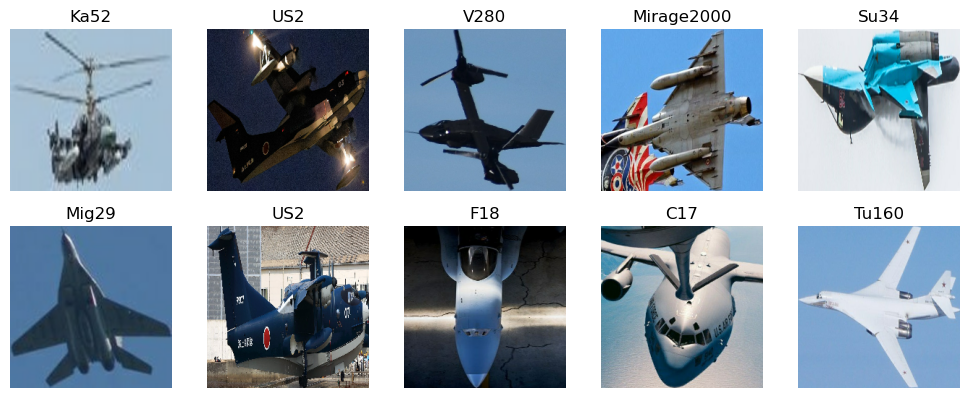

In [68]:
# Now let's visualize the data in training batch
train_images, train_labels = next(train_data.as_numpy_iterator()) # Convert the batch data to an iterator -> grab the next batch from the data that is 32
show_n_images(train_images, train_labels, n=10)

## **9. Build and Train Model**

### **Strategy: Transfer Learning**

Rather than training from scratch, we leverage **MobileNetV2** — a CNN pre-trained on 1.2M ImageNet images.

**Workflow:**
- The base model extracts visual features (edges, textures, patterns) — frozen, not retrained
- We attach a custom **101-neuron Dense layer** (one per aircraft class) — this layer alone is trained

| Component | Role | Trainable? |
|-----------|------|-----------|
| MobileNetV2 base | Visual feature extraction | ❌ Frozen |
| Dense output layer (101 units) | Class prediction | ✅ Trained |

---

### **Model Selection: MobileNetV2**

**Why MobileNetV2?**
- **Lightweight:** 3.4M parameters (fits in 4GB VRAM)
- **Fast inference:** Designed for mobile/edge devices
- **Proven:** Pre-trained ImageNet weights
- **Flexible:** Easy to upgrade to EfficientNet if needed

**Configuration:**
- **Variant:** MobileNetV2 (1.4x width multiplier)
- **Input shape:** `(224, 224, 3)` — normalized RGB
- **Output shape:** `(101,)` — one probability per aircraft class

---

### **Model Architecture**

```
Input: (224, 224, 3) ──→ MobileNetV2 (frozen) ──→ Dense(101) ──→ Output: (101,)
       RGB image         Feature extraction        Softmax      Aircraft probability
```

---

### **Upgrade Path (if accuracy insufficient)**

| Model | VRAM | ImageNet Training | Reference |
|-------|------|-------------------|-----------|
| **EfficientNetV2-B0** | ~4GB (local) | 21K classes (ft1k) | [Kaggle Models](https://www.kaggle.com/models/google/efficientnet-v2/tensorFlow2/imagenet21k-ft1k-b0-feature-vector/1) |
| **EfficientNetV2-B3** | ~16GB (Colab) | 21K classes (ft1k) | [Kaggle Models](https://www.kaggle.com/models/google/efficientnet-v2/tensorFlow2/imagenet21k-ft1k-b3-feature-vector/1) |

---
> **Note:** Both use `imagenet21k-ft1k` weights (pre-trained on 21K classes, fine-tuned on 1K) — strongest available for transfer learning.

---

**There are two ways to import a model:**
1. Either do as the kaggle ([eg. mobilenet_v2](https://www.kaggle.com/models/google/mobilenet-v2/tensorFlow2/140-224-feature-vector)) says which is fine (not used here because it caused compatibility issue and refers to legacy/old code.)
2. Use `tf.keras.applications.MODEL_NAME` and you can names at [Keras](https://keras.io/api/applications/) and at [TensorFlow](https://www.tensorflow.org/api_docs/python/tf/keras/applications)

In [ ]:
# Setting image size again before it was like (224, 224)
IMG_SIZE = 224

# Model constants

INPUT_SHAPE = (None, IMG_SIZE, IMG_SIZE, 3) # (Batch size ,height, width, colour channels)
OUTPUT_SHAPE = len(unique_classes) # Number of aircraft classes

: 

In [ ]:
# Create a function that builds a MobileNetV2 transfer learning model

def create_model_mobilenet(input_shape=INPUT_SHAPE,
                           output_shape=OUTPUT_SHAPE,
                           fine_tune_at=None):
    """
    Creates a MobileNetV2 transfer learning model for aircraft classification.

    Args:
        input_shape: Shape of input images
                     e.g. (None, 224, 224, 3)

        output_shape: Number of aircraft classes
                      e.g. 101

    Returns:
        A compiled TensorFlow/Keras model
    """

    print("Building MobileNetV2 transfer learning model...")

    # Load pretrained MobileNetV2 base model
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape[1:],   # Remove batch dimension
        include_top=False,             # Remove original ImageNet classifier
        weights="imagenet",            # Load pretrained ImageNet weights
        alpha=1.4                      # Wider MobileNetV2 version
    )

    # Freeze pretrained layers during initial training
    base_model.trainable = False

    # Build transfer learning architecture
    model = tf.keras.Sequential([

        # Feature extraction backbone
        base_model,

        # Convert feature maps into feature vector
        tf.keras.layers.GlobalAveragePooling2D(),

        # Final aircraft classification layer
        tf.keras.layers.Dense(
            units=output_shape,
            activation="softmax"
        )
    ])

    # Build model with full input shape
    model.build(input_shape=input_shape)

    # Configure training setup
    model.compile(

        # Multi-class classification loss function
        loss=tf.keras.losses.CategoricalCrossentropy(),

        # Optimizer updates model weights
        optimizer=tf.keras.optimizers.Adam(),

        metrics=[

            # Exact prediction accuracy
            "accuracy",

            # Checks if correct class exists in top 5 predictions
            tf.keras.metrics.TopKCategoricalAccuracy(
                k=5,
                name="top_5_accuracy"
            )
        ] 
    )

    return model

In [71]:
# Create MobileNetV2 model
mobilenet_model = create_model_mobilenet()

# View model architechture
mobilenet_model.summary()

Building MobileNetV2 transfer learning model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.40_224            │ (None, 7, 7, 1792)     │     4,363,712 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1792)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       181,093 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,544,805 (17.34 MB)

 Trainable params: 181,093 (707.39 KB)

 Non-trainable params: 4,363,712 (16.65 MB)

### **Understanding The Model Summary**

The pretrained MobileNetV2 model converts a `(224 × 224 × 3)` aircraft image into deep feature maps of shape `(7 × 7 × 1792)`.

- `7 × 7` → compressed version of the image
- `1792` → learned visual features like edges, textures, shapes, wings, engines, etc.

`GlobalAveragePooling2D()` converts these feature maps into a `1792-length` feature vector by averaging each feature channel.

The final `Dense(101, softmax)` layer acts as the aircraft classifier and predicts probabilities for all 101 aircraft classes.

### Parameter Understanding

- **Trainable Params** → only the custom classifier layer is being trained
- **Non-Trainable Params** → pretrained ImageNet knowledge remains frozen

This confirms that transfer learning is working correctly.


### **Model Data Flow**

```text
Input Image
(224 × 224 × 3)
        │
        ▼
MobileNetV2 CNN Backbone
Feature Extraction
        │
        ▼
Deep Feature Maps
(7 × 7 × 1792)
        │
        ▼
GlobalAveragePooling2D
Compress Feature Maps
        │
        ▼
Feature Vector
(1792)
        │
        ▼
Dense Layer + Softmax
Aircraft Classification
        │
        ▼
Output Probabilities
(101 Aircraft Classes)
```

### **Creating Callbacks**

Callbacks automate important tasks during training.

Used callbacks:
- **ModelCheckpoint** → saves best model
- **EarlyStopping** → stops bad training early
- **ReduceLROnPlateau** → lowers learning rate when learning slows
- **TensorBoard** → tracks training metrics

These improve:
- training stability
- monitoring
- model management

In [72]:
# Load Tensorboard notebook extention
%load_ext tensorboard

In [73]:
import datetime
import os

# Create a function to build a Tensorboard callback
def create_tensorboard_callback():
    # Create a log dictionary for storing Tensorboard logs
    logdir = os.path.join(str(LOG_DIR), datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
    os.makedirs(logdir, exist_ok=True)
    return tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [74]:
# Creating all the callbacks for the model

# Folder to save the best trained model
os.makedirs(MODEL_DIR, exist_ok=True)

# Function to create all training callbacks
def create_callbacks():
    return [
        
        # TensorBoard callback - Saves training logs for visualization
        create_tensorboard_callback(),
        
        # EarlyStopping callback - Stops training if validation loss stops improving
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",          # Metric to monitor
            patience=5,                  # Wait 5 epochs before stopping  # was 3
            restore_best_weights=True    # Restore best model weights
        ),
        
        # ReduceLROnPlateau callback - Lowers learning rate when training gets stuck 
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",   # Metric to monitor
            factor=0.2,           # Reduce LR by 80%
            patience=2,           # Wait 2 epochs before reducing LR  # was 3
            min_lr=1e-7           # Minimum learning rate
        ),
        
        # ModelCheckpoint callback - Saves the best model during training
        tf.keras.callbacks.ModelCheckpoint(
            filepath=os.path.join(
                MODEL_DIR,
                f"mobilenetv2_best_model_{datetime.datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.keras"
            ),
            monitor="val_loss",   # Save based on validation loss
            save_best_only=True   # Save only the best model
        )
    ]

#### **Callback Patience Tuning (Full Dataset)**

Subset training used `patience=3` for both EarlyStopping and ReduceLROnPlateau.
Full dataset epochs take longer — model needs more time to improve.

| Callback | Before | After | Reason |
|---|---|---|---|
| EarlyStopping | patience=3 | patience=5 | More time before stopping |
| ReduceLROnPlateau | patience=3 | patience=2 | Reduce LR before stopping kicks in |

**Order of events:** LR reduces at epoch 2 of no improvement → still stuck by epoch 5 → stop.

### **Epochs & EarlyStopping**

#### **What is an epoch?**
**One epoch** = model sees every training image once. 
- Too few = underfitting. 
- Too many = overfitting. 
> Let val_loss decide when to stop.

#### **How many epochs to run?**
- Don't pick a fixed number. 
- Set `epochs=50`, let `EarlyStopping` handle it.

#### **What is patience?**
How many epochs you wait after val_loss stops improving before stopping. 
> Val_loss is noisy — patience absorbs that noise.

#### **How to pick patience?**
`patience ≈ 10–20% of expected total epochs`

| Expected Epochs | Patience |
|---|---|
| 10 | 2–3 |
| 20–30 | 5–7 |
| 50+ | 8–12 |

Noisy data (class imbalance, small dataset) → higher patience.

## **10. Training on Subset of Data**

Before training on the full dataset,
a smaller subset of images is used first.

Purpose:
- verify training pipeline
- test callbacks
- check model learning
- validate predictions
- detect early issues quickly

This helps ensure the complete training setup works correctly before large-scale training.

In [75]:
train_data, val_data

(<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>,
 <_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>)

In [76]:
# Defining the number of epochs for a model
# Creating a slider for epoch selection

import ipywidgets as widgets
from IPython.display import display

# Use existing NUM_EPOCHS or default to 100
NUM_EPOCHS = globals().get("NUM_EPOCHS", 100)

# Create slider widget
num_epoch_slider = widgets.IntSlider(
    value=NUM_EPOCHS,          # Default value
    min=10,                    # Minimum epochs
    max=100,                   # Maximum epochs
    step=1,                    # Step size
    description="NUM_EPOCHS",  # Slider label
    continuous_update=False    # Update only after releasing slider
)

# Create label to display current value
num_epoch_label = widgets.Label(
    value=f"NUM_EPOCHS = {NUM_EPOCHS}"
)

# Function runs when slider value changes
def on_num_epochs_change(change):
    global NUM_EPOCHS
    
    # Update global variable
    NUM_EPOCHS = change["new"]
    
    # Update label text
    num_epoch_label.value = f"NUM_EPOCHS = {NUM_EPOCHS}"

# Watch slider "value" changes
num_epoch_slider.observe(on_num_epochs_change, names="value")

# Display slider and label
display(num_epoch_slider, num_epoch_label)

IntSlider(value=100, continuous_update=False, description='NUM_EPOCHS', min=10)

Label(value='NUM_EPOCHS = 100')

In [77]:
# Function to train the MobileNetV2 model

def train_model(train_data, val_data, epochs=NUM_EPOCHS, class_weight=None):
    """
    Trains the MobileNetV2 aircraft classification model.
    
    Args:
        train_data:
            Training dataset batches.
        val_data:
            Validation dataset batches.   
        epochs:
            Number of training epochs.
        class_weight:
            Optional dictionary mapping class indexes to weights.
            Pass class_weight_dict to penalise rare class mistakes more.
            Default is None (no weighting applied).
    Returns:
        Trained TensorFlow model.
    """
    
    # Instantiate the model
    model = create_model_mobilenet(
        input_shape=INPUT_SHAPE,
        output_shape=OUTPUT_SHAPE
    )
    
    # Instantiate training callbacks
    callbacks = create_callbacks()
    
    # Train the model
    model.fit(
        x=train_data,
        epochs=epochs,
        validation_data=val_data,
        callbacks=callbacks,
        class_weight=class_weight  # None = no weighting, dict = weighted training
    )
    
    print("Training of model: Done..")
    
    # Return trained model
    return model

In [78]:
# Taking random sample rows from Train and Validation dataset
train_subset = train_df.sample(1000)
val_subset = val_df.sample(1000)

X_train_subset, y_train_subset = get_X_and_y(train_subset)
X_val_subset, y_val_subset = get_X_and_y(val_subset)

train_subset_data = create_data_batches(X_train_subset, y_train_subset)
val_subset_data = create_data_batches(X_val_subset, y_val_subset, valid_data=True)

Creating training data batches...
Creating validation data batches...


In [79]:
# # Training the model on subset of data

# subset_model = train_model(
#     train_data=train_subset_data,
#     val_data=val_subset_data,
#     epochs=NUM_EPOCHS
# )

# Model already trained and saved 

Its looks like our model is overfitting because it's performing far better on the training dataset than on validation dataset

In [80]:
# !nvidia-smi

### **Checking the Tensorboard Logs**

The Tensorboard magic command (`%tensorboard`) will access the logs directory we created and visualize its contents.

In [81]:
import os
print(os.listdir(LOG_DIR))

['2026-05-13 09:37:58', '2026-05-13 09:40:57', '2026-05-15 21:28:50', '2026-05-16 03:59:34', '2026-05-16 04:08:44']


In [82]:
# To kill all the running Tensorboard sessions
!pkill -f tensorboard

In [83]:
# logdir = LOG_DIR
# # %tensorboard --logdir $logdir
# !tensorboard --logdir $logdir --port 6006

In [84]:
# # To kill all the running Tensorboard sessions
# !pkill -f tensorboard

## **11. Making and Evaluating predictions using a trained model**

### **Make Predictions**

Runing `model.predict()` on **val_data**

In [85]:
# This block reloads the saved subset model using the project directory instead of a hardcoded path
saved_subset_models = sorted(RELEASE_MODELS_DIR.glob("1000-images-mobinetv2-Adam_*.keras"))
if not saved_subset_models:
    raise FileNotFoundError(
        f"No saved subset model found in {RELEASE_MODELS_DIR}. Run the save step first."
    )

subset_model = tf.keras.models.load_model(saved_subset_models[-1])

In [86]:
# Make predictions on the validation set (not used to train on)
small_prediction = subset_model.predict(val_subset_data,
                                        verbose=1)
small_prediction

I0000 00:00:1778954907.402785    1922 service.cc:145] XLA service 0x7cded0003340 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778954907.402932    1922 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6
I0000 00:00:1778954909.707158    2055 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_1150', 128 bytes spill stores, 128 bytes spill loads



 3/63 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step 

I0000 00:00:1778954925.887082    1922 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step

I0000 00:00:1778954932.562757    2150 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_1150', 148 bytes spill stores, 148 bytes spill loads



63/63 ━━━━━━━━━━━━━━━━━━━━ 40s 294ms/step


array([[5.0683287e-03, 9.1183549e-03, 4.3096980e-03, ..., 1.2499923e-03,
        3.0830616e-04, 7.6174792e-06],
       [1.5178642e-03, 7.4065296e-04, 3.4011891e-03, ..., 1.6739412e-03,
        6.9054782e-05, 5.0325330e-06],
       [6.2118028e-03, 1.1634059e-02, 4.1137612e-04, ..., 9.9054249e-03,
        2.8974417e-04, 4.0620576e-05],
       ...,
       [1.3220568e-02, 2.1266118e-03, 1.4761379e-03, ..., 1.5362733e-03,
        1.0823597e-04, 6.7787398e-05],
       [1.3453994e-02, 3.0592398e-03, 1.5396975e-03, ..., 9.0976087e-03,
        3.4254594e-04, 4.3254277e-06],
       [1.0224450e-02, 1.0154532e-02, 1.2682936e-03, ..., 8.6652134e-03,
        4.8128294e-04, 6.7142677e-04]], dtype=float32)

In [87]:
# 1000 rows with each having 101 prediction probabilities
small_prediction.shape, len(small_prediction[0])

((1000, 101), 101)

In [88]:
# For first prediction
index = 1
print("Predicted probabilities", small_prediction[index])
print(f"Max value (probability of predictions): {np.max(small_prediction[index])}")
print(f"Sum: {np.sum(small_prediction[index])}")
print(f"Max label index: {np.argmax(small_prediction[index])}")
print(f"Predicted label: {unique_classes[np.argmax(small_prediction[index])]}")

Predicted probabilities [1.51786418e-03 7.40652962e-04 3.40118911e-03 2.81562592e-04
 4.43100771e-06 1.15569159e-02 1.94659978e-02 1.68698789e-05
 3.29259251e-07 2.73523590e-04 7.87418243e-03 7.89047964e-03
 4.86020042e-07 2.79299403e-03 3.85885905e-05 7.08544627e-04
 1.16738409e-03 1.09536126e-02 1.36384784e-04 6.95253722e-04
 9.83042410e-04 4.95637162e-03 1.09942192e-02 3.17154336e-04
 1.71399638e-02 7.75209264e-06 2.77726213e-03 5.24641154e-03
 2.63574912e-04 7.71722849e-03 3.41223568e-01 1.55125365e-01
 3.62164876e-03 1.01257942e-03 2.29251347e-02 1.20631464e-01
 9.34038684e-03 6.38190477e-06 2.76216248e-04 3.37745459e-03
 6.78100437e-02 2.09092628e-03 1.41190367e-06 7.54137830e-07
 6.86236135e-08 8.66967894e-04 1.15798168e-04 6.18836901e-04
 8.77098282e-05 3.00616113e-04 4.35732654e-04 1.71470742e-06
 3.51826529e-05 2.99356827e-07 1.43248343e-03 1.10300721e-06
 9.88464380e-05 5.55953709e-04 1.57716754e-03 5.91421442e-04
 3.33554744e-05 8.33491678e-04 9.29342292e-04 9.53409544e-05


In [89]:
unique_classes

array(['A10', 'A400M', 'AG600', 'AH64', 'AKINCI', 'AV8B', 'An124', 'An22',
       'An225', 'An72', 'B1', 'B2', 'B21', 'B52', 'Be200', 'C1', 'C130',
       'C17', 'C2', 'C390', 'C5', 'CH47', 'CH53', 'CL415', 'E2', 'E7',
       'EF2000', 'EMB314', 'F117', 'F14', 'F15', 'F16', 'F18', 'F2',
       'F22', 'F35', 'F4', 'FCK1', 'H6', 'Il76', 'J10', 'J20', 'J35',
       'J36', 'J50', 'JAS39', 'JF17', 'JH7', 'KAAN', 'KC135', 'KF21',
       'KIZILELMA', 'KJ600', 'Ka27', 'Ka52', 'MQ20', 'MQ25', 'MQ28',
       'MQ9', 'Mi24', 'Mi26', 'Mi28', 'Mi8', 'Mig29', 'Mig31',
       'Mirage2000', 'NH90', 'P3', 'RQ4', 'Rafale', 'SR71', 'Su24',
       'Su25', 'Su34', 'Su47', 'Su57', 'T50', 'TB001', 'TB2', 'Tejas',
       'Tornado', 'Tu160', 'Tu22M', 'Tu95', 'U2', 'UH60', 'US2', 'V22',
       'V280', 'Vulcan', 'WZ10', 'WZ7', 'WZ9', 'X29', 'X32', 'XB70',
       'XQ58', 'Y20', 'YF23', 'Z10', 'Z19'], dtype='<U10')

**Let's create a function to get the predicted label and visualize the predicted image**

In [90]:
# Turn prediction probabilities into respective labels
def get_pred_label(prediction_probabilities):
    """
    Turn the Array of prediction probilities into label
    Args:
        len(predictions probabilities) = 101
    """
    return unique_classes[np.argmax(prediction_probabilities)]

# Get the predicted label based on araay of prediction probabilities
pred_label = get_pred_label(small_prediction[2])
pred_label

'JAS39'


### **Unbatching Validation Data**

`val_data` is a batched `tf.data` pipeline. Images are grouped in batches of 32. To compare predictions against true labels visually, we need:

- Individual images → to display
- Individual true labels → to compare against predicted labels

**Unbatching** flattens the pipeline back to one image at a time.

After unbatching we can iterate through and pull images + labels as separate arrays.



In [91]:
val_subset_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>

In [92]:
# Create a function to unbatch a batched dataset

def unbatch_dataset(dataset):
    """
    Unbatch a batched tf.data dataset into separate image and label arrays.

    Args:
        dataset (tf.data.Dataset): Batched dataset of (image, label) tensor pairs.

    Returns:
        tuple: 
            images (list): List of numpy arrays, each of shape (224, 224, 3).
            labels (list): List of numpy arrays, each of shape (101,) one-hot encoded.
    """
    
    images = []
    labels = []
    
    # Loop through unbatch data
    for image, label in dataset.unbatch().as_numpy_iterator():
        images.append(image)
        labels.append(unique_classes[np.argmax(label)])
        
    return images, labels


# Unbatchify the validation data
val_subset_images, val_subset_labels = unbatch_dataset(val_subset_data)
val_subset_images[0], val_subset_labels[0]

(array([[[0.39939728, 0.528809  , 0.73665214],
         [0.39983004, 0.5292418 , 0.7370849 ],
         [0.39995366, 0.5218899 , 0.7334708 ],
         ...,
         [0.40000004, 0.52156866, 0.73333335],
         [0.40242845, 0.52399707, 0.73576176],
         [0.40293247, 0.5245011 , 0.7362658 ]],
 
        [[0.39645118, 0.52586293, 0.73370606],
         [0.39686862, 0.52628034, 0.73412347],
         [0.39981622, 0.5217525 , 0.73333335],
         ...,
         [0.40282837, 0.524397  , 0.7361617 ],
         [0.40000004, 0.52156866, 0.73333335],
         [0.40000004, 0.52156866, 0.73333335]],
 
        [[0.39607847, 0.5254902 , 0.73333335],
         [0.3945563 , 0.5239681 , 0.7318112 ],
         [0.3996324 , 0.52156866, 0.7331495 ],
         ...,
         [0.40276164, 0.52433026, 0.73609495],
         [0.40000004, 0.52156866, 0.73333335],
         [0.4027898 , 0.52435845, 0.73612314]],
 
        ...,
 
        [[0.39761034, 0.5191789 , 0.7309436 ],
         [0.4039216 , 0.5254902 , 0.73725

In [93]:
len(val_subset_images), val_subset_labels[0].shape

(1000, ())

- `val_subset_images` -> List of 1000 aircrafts images
- `val_subset_labels` -> List of 1000 aircraft names

In [94]:
val_subset_labels[0]

'An124'

In [95]:
# for first image cross checking predicted and truth val label
pred = get_pred_label(small_prediction[0])
truth = get_pred_label(val_subset_labels[0])
pred, truth

('Tu160', 'A10')

**Now we've got the:**

- Prediction labels (1000)
- Validation labels (1000)
- Validation images (1000)

Let's make some function to make these all a bit more vizualize.

**For the Function:**
- Takes an array of prediction probabilities and array of truth labels and an array of image and an integer.
- Convert the predictions probabilities to predicted label.
- Plot the predicted label, its's prediction probability, truth label and the target image on a single plot.

In [96]:
def plot_predictions(prediction_probabilities,
                     labels,
                     images,
                     n=1):
    """
    Plot a prediction with confidence score and ground truth label.

    Title color:
    - Blue  -> correct prediction
    - Coral -> incorrect prediction

    Args:
        prediction_probabilities (np.ndarray):
            Array of prediction probabilities of shape (N, num_classes)

        labels (list):
            List of true class labels

        images (list):
            List of image filepaths or processed image arrays

        n (int):
            Index of sample to visualize
    """

    # Get prediction probability, true label, and image
    pred_prob = prediction_probabilities[n]
    true_label = labels[n]
    image = images[n]

    # Process image only if input is a filepath
    if isinstance(image, str):
        image = process_image(image)

    # Convert tensor to numpy array if needed
    if tf.is_tensor(image):
        image = image.numpy()

    # Get predicted label
    pred_label = get_pred_label(pred_prob)

    # Set title color based on prediction correctness
    color = "blue" if pred_label == true_label else "coral"

    # Plot image
    plt.imshow(image)
    plt.axis("off")

    # Plot title
    plt.title(
        f"{pred_label} | {np.max(pred_prob)*100:.2f}% | True: {true_label}",
        color=color
    )

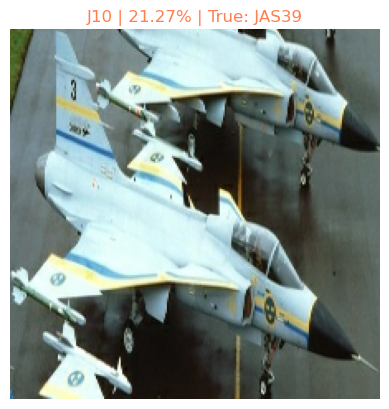

In [97]:
# Lets see our predictions

plot_predictions(prediction_probabilities=small_prediction,
          labels=val_subset_labels,
          images=val_subset_images,
          n=5)

# Correct -> blue, wrong -> coral

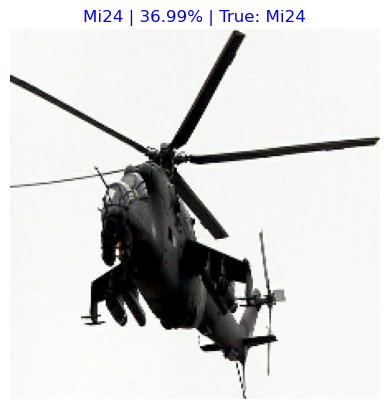

In [98]:
plot_predictions(prediction_probabilities=small_prediction,
          labels=val_subset_labels,
          images=val_subset_images,
          n=52)

In [99]:
small_prediction

array([[5.0683287e-03, 9.1183549e-03, 4.3096980e-03, ..., 1.2499923e-03,
        3.0830616e-04, 7.6174792e-06],
       [1.5178642e-03, 7.4065296e-04, 3.4011891e-03, ..., 1.6739412e-03,
        6.9054782e-05, 5.0325330e-06],
       [6.2118028e-03, 1.1634059e-02, 4.1137612e-04, ..., 9.9054249e-03,
        2.8974417e-04, 4.0620576e-05],
       ...,
       [1.3220568e-02, 2.1266118e-03, 1.4761379e-03, ..., 1.5362733e-03,
        1.0823597e-04, 6.7787398e-05],
       [1.3453994e-02, 3.0592398e-03, 1.5396975e-03, ..., 9.0976087e-03,
        3.4254594e-04, 4.3254277e-06],
       [1.0224450e-02, 1.0154532e-02, 1.2682936e-03, ..., 8.6652134e-03,
        4.8128294e-04, 6.7142677e-04]], dtype=float32)

Now we've got the fucton to visualize our model's top confidence predictions, let's make a another function to view our model's **top 10 predictions.**

**The function will:**
- Take an input of prediction probabilities array, a ground truth array, and an integer.
- Find the predictive label using `get_pred_labels()`.
- Find the Top 10:
  - Prediction probabilities indexes
  - Prediction probabilities values
  - Prediction labels
- Plot the top 10 prediction probability and labels, colouring the true label `green`

In [100]:
small_prediction.shape

(1000, 101)

In [101]:
def plot_top_10_pred_conf(prediction_probabilities, labels, n=1):
    """
    Plots a bar chart of the top 10 prediction confidences for a given sample.
    The bar for the true label is highlighted in green if it appears in the top 10.

    Args:
        - prediction_probabilities (np.ndarray): 2D array of prediction probabilities,
                                                shape (num_samples, num_classes).
        - labels (array-like): Array of true labels corresponding to each sample.
        - n (int, optional): Index of the sample to visualize. Defaults to 1.
    """
    pred_prob, true_label = prediction_probabilities[n], labels[n]
    
    # Get the prediction label
    pred_label = get_pred_label(pred_prob)

    # Get the top 10 prediction indexes
    top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]    # indices sorted by value, LOW → HIGH and reverse → now HIGH → LOW
    
    # Get the top 10 prediction confidence values
    top_10_pred_values = pred_prob[top_10_pred_indexes]
    
    # Get the top 10 prediction labels
    top_10_pred_labels = unique_classes[top_10_pred_indexes]
    
    # Setup plot
    top_10_plot = plt.bar(x=np.arange(len(top_10_pred_labels)),
                          height=top_10_pred_values,
                          color="grey")
    plt.xticks(np.arange(len(top_10_pred_labels)),
               labels=top_10_pred_labels,
               rotation="vertical")
    plt.title(f"Predicted: {pred_label} | True: {true_label}")
    # Change the colour of true label -> green
    if np.isin(true_label, top_10_pred_labels):
        top_10_plot[np.argmax(top_10_pred_labels==true_label)].set_color("green")
    else:
        pass

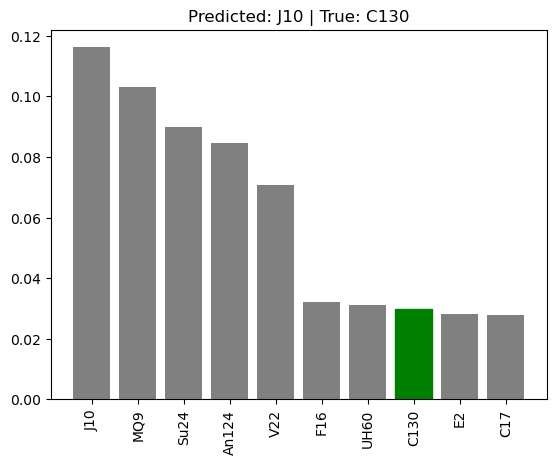

In [102]:
# Visualizing top 10 predictions
plot_top_10_pred_conf(prediction_probabilities=small_prediction,
                      labels=val_subset_labels,
                      n=27)

**Now we've got some functions to help visualize our predictions and evaluate our model, let's check out few.**

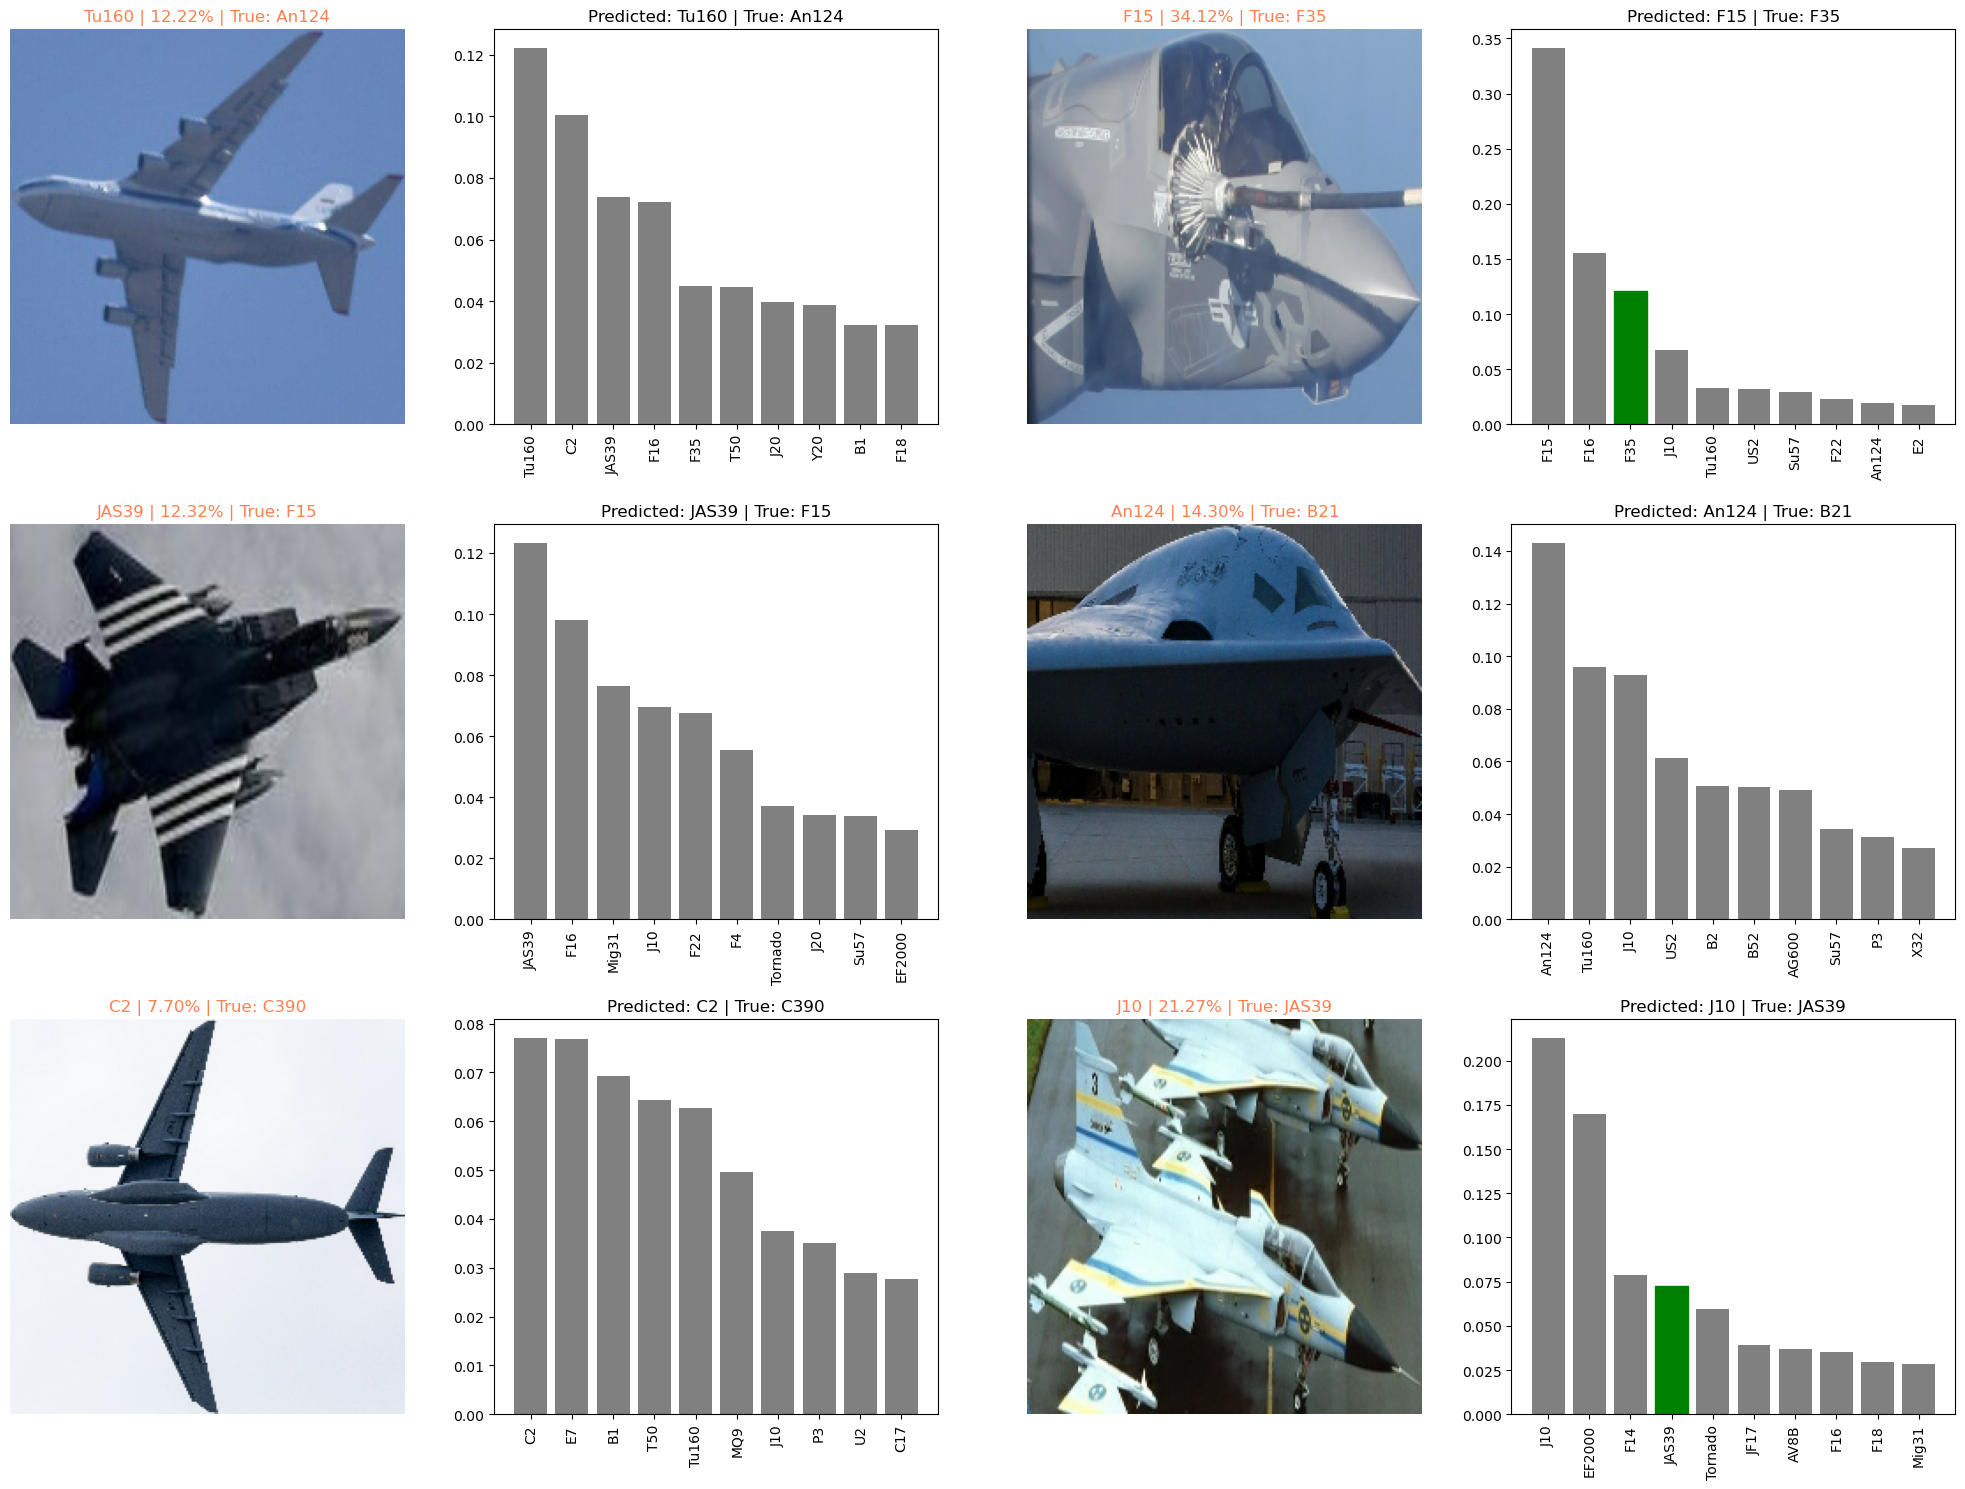

In [103]:
# Let's checkout out few predictions and their different value
i_multiplier = 0
num_rows = 3
num_cols = 2
num_images = num_rows*num_cols

# Plotting the figure
plt.figure(figsize=(10*num_cols, 5*num_rows))  # width -> cols, height -> rows

for i in range(num_images):
    plt.subplot(num_rows, 2*num_cols, 2*i+1)   # (rows, columns, cell number)
    plot_predictions(prediction_probabilities=small_prediction,
                     labels=val_subset_labels,
                     images=val_subset_images,
                     n=i+i_multiplier)  # n=i+i_multiplier is just the image index. Eg. Starting from dog #20, then #21, then #22 and so on
    plt.subplot(num_rows, 2*num_cols, 2*i+2)
    plot_top_10_pred_conf(prediction_probabilities=small_prediction,
                          labels=val_subset_labels,
                          n=i+i_multiplier)

# Everything looks nice 
plt.tight_layout()
plt.show()

## **12. Saving and reloading a trained model**

In [104]:
RELEASE_MODELS_DIR.exists()

True

In [105]:
# Function to save a model

def save_model(model, suffix="model"):
    """
    Saves a trained model inside release_models directory.

    Args:
        model:
            Trained TensorFlow model.

        suffix:
            Custom name for the saved model.

    Returns:
        Saved model path.
    """

    # Create release_models directory
    os.makedirs(RELEASE_MODELS_DIR, exist_ok=True)

    # Create timestamp
    timestamp = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

    # Create final model path
    model_path = os.path.join(
        RELEASE_MODELS_DIR,
        f"{suffix}_{timestamp}.keras"
    )

    # Save the model
    print(f"Saving model to: {model_path}")
    model.save(model_path)

    print("Model saved successfully.")

    return model_path

# release_models/
# └── mobilenetv2_full_data_2026-05-12_08-15-44.keras

In [106]:
# Function to load a trained model

def load_model(model_path):
    """
    Loads a saved TensorFlow model.

    Args:
        model_path:
            Path to the saved model file.

    Returns:
        Loaded TensorFlow model.
    """

    print(f"Loading model from: {model_path}...")

    model = tf.keras.models.load_model(model_path)

    print("Model loaded successfully.")

    return model

In [107]:
# # Save our model trained on 1000 images
# save_model(model=subset_model, suffix="1000-images-mobinetv2-Adam")

In [108]:
# Load the trained model
saved_models = sorted(RELEASE_MODELS_DIR.glob("1000-images-mobinetv2-Adam_*.keras"))
if not saved_models:
    raise FileNotFoundError(
        f"No saved model found in {RELEASE_MODELS_DIR}. Run the save step first."
    )

loaded_1000_images_model = load_model(saved_models[-1])

Loading model from: ../release_models/1000-images-mobinetv2-Adam_2026-05-13_09-40-38.keras...
Model loaded successfully.


In [109]:
# Evalute the laoded model
loaded_1000_images_model.evaluate(val_subset_data)

63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 126ms/step - accuracy: 0.1410 - loss: 4.0343 - top_5_accuracy: 0.3510


[4.034251689910889, 0.14100000262260437, 0.35100001096725464]

### **Subset Model Evaluation**

```python
loaded_1000_images_model.evaluate(val_subset_data)
# [3.924, 0.156, 0.389]
# [loss,  accuracy,  top_5_accuracy]
```

- **Val Accuracy:** ~16%
- **Top-5 Accuracy:** ~40%
- **Random chance baseline:** ~1% (101 classes)

Model has learned something but needs full dataset — expected behaviour for 1000 images.

---

## **13. Training a big aircraft classifier 🛦**

### **13.1 Handling Class Imbalance Before Full Training**

#### **Why It Matters**

With 41k images across 101 classes, significant imbalance exists.
Common classes (F-16, F-18) have 1000+ images. Rare classes (J-50, WZ-10) have ~40.

A model trained on imbalanced data gets biased toward majority classes.
It learns to guess F-16 often because that guess gets rewarded more during training.
Rare classes get predicted almost never — even if overall accuracy looks okay.

---

#### **Three Approaches**

| Approach | What It Does | Downside |
|---|---|---|
| Oversampling | Duplicate/augment rare class images | Modifies data pipeline |
| Undersampling | Remove majority class images | Throws away real data |
| Class Weights | Penalise mistakes on rare classes more | Nothing — best fit here |

**Class weights chosen** — zero changes to the existing data pipeline.
Instead of changing how much data each class gets, we change how much each mistake costs.

---

#### **Computing Class Weights**

**Formula used internally:**
`weight = total_samples / (num_classes × samples_in_that_class)`

Rarer class → higher weight → mistakes on it cost more → model pays attention.

> Note: `compute_class_weight` needs integer labels, not one-hot encoded arrays.

In [110]:
y_train

array([[1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1]])

In [111]:
# Convert one-hot encoded labels to integer class indexes
# e.g. [0,0,1,0...] → 2
y_train_max_indexes = np.argmax(y_train, axis=1)
y_train_max_indexes

array([  0,   0,   0, ..., 100, 100, 100])

In [112]:
# Gives all the 101 classes ranging from 0 to 100
np.unique(y_train_max_indexes)

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100])

In [113]:
# Number of image label indexes
len(y_train_max_indexes)

31127

In [114]:
# Compute how much weight each class should get during training
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_max_indexes),
    y=y_train_max_indexes
)
class_weights

# 'balanced' = rare classes get higher weights automatically
# classes = all unique class indexes (0 to 100)
# y = the integer labels to count from

array([ 0.5119404 ,  0.77825283,  1.48883149,  0.71505364,  2.75167963,
        0.94247131,  1.78143421,  3.24408546,  3.80479159,  2.18573134,
        0.60906743,  0.70042754,  6.42058581,  0.65993173,  1.35765691,
        1.58859855,  0.25470092,  0.55629624,  0.53504882,  1.98831044,
        0.98778243,  1.13722553,  3.42431243,  0.99095858,  0.87305416,
        1.81287129,  0.48305348,  1.3114388 ,  1.09286567,  0.74262197,
        0.26184207,  0.20077402,  0.22429994,  2.48538805,  0.54163114,
        0.258114  ,  0.58814526,  3.38668262,  0.83519815,  1.35170228,
        0.5454657 ,  0.45056743,  2.82741393,  4.22175505,  7.33781235,
        0.66419853,  1.40725168,  1.37583982,  4.46649448,  0.92548985,
        3.24408546,  5.70718739,  3.71310987,  2.56823432,  1.45371754,
       38.52351485,  6.04290429,  9.3390339 ,  1.04825891,  1.04825891,
        2.93512494,  1.74117581,  1.30037181,  0.95414278,  0.80677518,
        0.84435101,  5.31358826,  0.75351618,  1.35170228,  0.51

In [115]:
# Keras needs it as a dictionary where the key is the class index
class_weights_dict = dict(enumerate(class_weights))
class_weights_dict

{0: 0.511940396697477,
 1: 0.7782528252825283,
 2: 1.4888314918448367,
 3: 0.7150536399347591,
 4: 2.751679632248939,
 5: 0.9424713113513186,
 6: 1.7814342127854403,
 7: 3.2440854611776966,
 8: 3.804791590270138,
 9: 2.185731339091356,
 10: 0.6090674284819786,
 11: 0.7004275427542754,
 12: 6.420585808580858,
 13: 0.6599317319312231,
 14: 1.3576569110655559,
 15: 1.588598550576707,
 16: 0.2547009246379183,
 17: 0.5562962433427459,
 18: 0.5350488173817382,
 19: 1.9883104439476205,
 20: 0.9877824320893628,
 21: 1.1372255306711483,
 22: 3.4243124312431243,
 23: 0.9909585813886855,
 24: 0.8730541609401733,
 25: 1.812871287128713,
 26: 0.48305347776156926,
 27: 1.3114388034548137,
 28: 1.092865669545678,
 29: 0.7426219730406776,
 30: 0.26184207205767307,
 31: 0.20077401876995518,
 32: 0.22429994091112168,
 33: 2.4853880549345257,
 34: 0.5416311402669265,
 35: 0.25811400235500936,
 36: 0.5881452649081702,
 37: 3.3866826243063866,
 38: 0.8351981539617377,
 39: 1.3517022754907069,
 40: 0.545465

In [116]:
# Training data
len(X_train), len(y_train)

(31127, 31127)

In [117]:
# Validation data
len(X_val), len(y_val)

(7545, 7545)

In [118]:
# Test data
len(X_test), len(y_test)

(2769, 2769)

In [119]:
# Training batch data, Validation batch data, testing batch data
print(train_data)
print(val_data)
print(test_data)

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>
<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>
<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>


In [120]:
# # Fit the model to the full data
# model = train_model(train_data=train_data,
#                     val_data=val_data,
#                     epochs=NUM_EPOCHS,
#                     class_weight=class_weights_dict)

`nvidia-smi`: run it in a separate terminal to monitor GPU usage.

### **13.2 Full Dataset Training Results (Frozen Backbone)**

#### **Training Summary**

- Epochs ran: 17 (EarlyStopping triggered)
- Best epoch: 12
- Best weights restored automatically by EarlyStopping

#### **Results**

| Metric | Subset | Full Dataset |
|---|---|---|
| val_accuracy | 15% | 46.4% |
| val_top_5_accuracy | 39% | 73.1% |
| val_loss | — | 2.48 |

Random guessing on 101 classes = ~1%. Frozen backbone ceiling reached at ~46%.

#### **What Happened During Training**

| Epoch | Event |
|---|---|
| 1-7 | LR = 0.001, model learning fast |
| 8 | ReduceLROnPlateau fired → LR dropped to 0.0002, val accuracy jumped from 41% → 45% |
| 12 | Best val_loss achieved (2.480) |
| 12-17 | LR kept dropping, val accuracy plateaued — frozen backbone ceiling hit |
| 17 | EarlyStopping triggered, best weights from epoch 12 restored |

#### **Next Step**

**Fine-tuning:** unfreeze top layers of MobileNetV2 and let them adapt to aircraft images.
Expected improvement: val_accuracy 55-65%+

In [121]:
# # Save the model trained in whole training dataset
# save_model(model, "atas_baseline_mobilenetv2_full_adam_v1")

---

## **14. Making Predictions Using Model Trained on Whole Training Dataset**

Using the full trained MobileNetV2 model to generate predictions on the validation set.

Each prediction returns a probability distribution across all 101 aircraft classes.

In [122]:
# Loading the baseline model from the project release-models directory
baseline_models = sorted(RELEASE_MODELS_DIR.glob("atas_baseline_mobilenetv2_full_adam_v1_*.keras"))
if not baseline_models:
    raise FileNotFoundError(
        f"No baseline model found in {RELEASE_MODELS_DIR}. Run the save step first."
    )

baseline_model = load_model(baseline_models[-1])

Loading model from: ../release_models/atas_baseline_mobilenetv2_full_adam_v1_2026-05-13_12-23-17.keras...
Model loaded successfully.


In [123]:
# Function to make predictions using the trained model
def make_predictions(model, data_batches, verbose=1):
    """
    Generate predictions using a trained TensorFlow/Keras model.

    Args:
        model: Trained model
        data_batches: Batched input data
        verbose: Verbosity level for predictions

    Returns:
        predictions: Model prediction outputs
    """

    print("Starting predictions...")

    predictions = model.predict(data_batches, verbose=verbose)

    print("Predictions completed successfully.")

    return predictions

In [124]:
# # Make predictions on Validation data batch using the loaded full model
# basline_predictions = make_predictions(model=baseline_model,
#                                        data_batches=val_data)

In [125]:
import datetime

# Directory to save prediction files
PREDICTION_DIR = PROJECT_ROOT / "predictions"

# Function to save predictions
def save_predictions(predictions,
                     file_suffix="baseline",
                     save_to=PREDICTION_DIR):
    """
    Save model predictions as a CSV file with timestamp.

    Args:
        predictions: NumPy array of predictions
        file_suffix: Custom suffix for filename
        save_to: Directory path to save predictions
    """

    # Create directory if it doesn't exist
    save_to.mkdir(parents=True, exist_ok=True)

    # Generate timestamp
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")

    # Create filename
    filename = f"{file_suffix}_predictions_{timestamp}.csv"

    save_path = save_to / filename

    print("Saving predictions to CSV file...")

    np.savetxt(
        save_path,
        predictions,
        delimiter=","
    )

    print(f"Predictions saved successfully at: {save_path}")

In [126]:
# Function to load saved predictions
def load_predictions(file_path):
    """
    Load prediction values from a CSV file.

    Args:
        file_path: Path to prediction CSV file

    Returns:
        predictions: Loaded NumPy array
    """

    print("Loading predictions from CSV file...")

    predictions = np.loadtxt(
        file_path,
        delimiter=","
    )

    print("Predictions loaded successfully.")

    return predictions

In [127]:
# # Saving the predictions
# save_predictions(predictions=basline_predictions,
#                  file_suffix="mobilenetv2_full")

In [128]:
# Load the predictions from the project predictions directory
prediction_files = sorted(PREDICTION_DIR.glob("mobilenetv2_full_predictions_*.csv"))
if not prediction_files:
    raise FileNotFoundError(
        f"No prediction CSV found in {PREDICTION_DIR}. Run the save step first."
    )

basline_predictions = load_predictions(prediction_files[-1])
basline_predictions.shape

Loading predictions from CSV file...
Predictions loaded successfully.


(7545, 101)

In [129]:
# Checking shape of baseline_predictions
basline_predictions.shape

(7545, 101)

In [130]:
# Testing the validation dataset in batch
val_data

# Validation dataset is already available separately as X_val and y_val.
# Avoid unbatching the full tf.data dataset to prevent excessive memory usage
# and potential kernel crashes.

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>

In [177]:
# Loading validation images and labels
val_images, val_labels = val_images_processed = X_val, y_val

len(val_images), len(val_labels), basline_predictions.shape

(7545, 7545, (7545, 101))

In [132]:
val_images

<StringArray>
['../data/crop/A10/c00aa3e8b7fe8ddcaee8b927c0aee8c2_0.jpg',
 '../data/crop/A10/c013d8c11f35868538e7ef4207fe35e2_0.jpg',
 '../data/crop/A10/c013d8c11f35868538e7ef4207fe35e2_1.jpg',
 '../data/crop/A10/c054a86ad655707e333fb2834b384b9e_0.jpg',
 '../data/crop/A10/c054a86ad655707e333fb2834b384b9e_1.jpg',
 '../data/crop/A10/c081f802e30166098628cdc7df1b5e0e_0.jpg',
 '../data/crop/A10/c081f802e30166098628cdc7df1b5e0e_1.jpg',
 '../data/crop/A10/c11b2e2b22bf3fc9f91ffebb7b6e0f4d_1.jpg',
 '../data/crop/A10/c240fa1e2f6a6f93cc33610c300dcf2f_0.jpg',
 '../data/crop/A10/c28a0faa030ede75615db89544d41b9b_2.jpg',
 ...
 '../data/crop/Z19/e1b72552440fa93b60f0d1d2aa02ee7c_5.jpg',
 '../data/crop/Z19/e1b72552440fa93b60f0d1d2aa02ee7c_6.jpg',
 '../data/crop/Z19/e1b72552440fa93b60f0d1d2aa02ee7c_7.jpg',
 '../data/crop/Z19/e1b72552440fa93b60f0d1d2aa02ee7c_8.jpg',
 '../data/crop/Z19/e1b72552440fa93b60f0d1d2aa02ee7c_9.jpg',
 '../data/crop/Z19/e25da44dfdaad19bc7416d8db1814a85_1.jpg',
 '../data/crop/Z19/e4

In [133]:
len(y_val)

7545

In [134]:
# Turn prediction probailitie into their respective labels
pred_labels = unique_classes[np.argmax(basline_predictions, axis=1)]
pred_labels

array(['E2', 'A10', 'A10', ..., 'Z19', 'Z10', 'Z19'], dtype='<U10')

In [135]:
# Turn Validation label probabilties into their respective true labels
true_labels = unique_classes[np.argmax(val_labels, axis=1)]
true_labels

array(['A10', 'A10', 'A10', ..., 'Z19', 'Z19', 'Z19'], dtype='<U10')

In [136]:
# Checking length of labels
len(true_labels), len(pred_labels)

(7545, 7545)

- `baseline_predictions` — raw probability outputs, shape `(7545, 101)`
- `pred_labels` — predicted class names via argmax
- `true_labels` — ground truth class names from validation set

Predictions saved to `predictions/` for reuse without re-running inference.

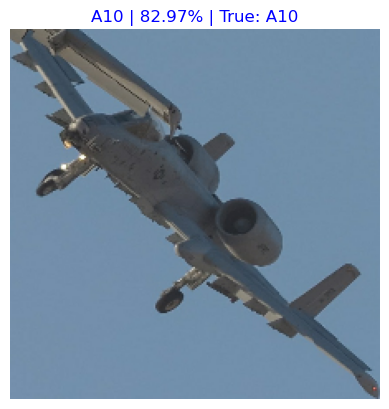

In [137]:
# Plotting some Predictions with truth labels
plot_predictions(prediction_probabilities=basline_predictions,
                 labels=true_labels,
                 images=val_images,
                 n=1)

---

## **15. Confusion Matrix & Per-Class Analysis**

With baseline predictions generated on the full validation set, we now analyze *where* the model succeeds and where it fails.

### **Work in this section:**

1. **Build the confusion matrix** — 101×101 grid of true vs. predicted classes
2. **Per-class accuracy** — extract how well the model handles each of the 101 aircraft individually
3. **Identify hardest classes** — find which aircraft the model struggles with most
4. **Visualize confusion** — heatmap of the most confused class pairs
5. **Confusion pair analysis** — which two aircraft get mixed up most often, and why

### **Why this matters before fine-tuning:**

Fine-tuning without this analysis is flying blind. The confusion matrix tells us:
- Whether low accuracy is spread evenly or concentrated in a few problem classes
- Which classes might need targeted data augmentation or class weight adjustments in a future training run
- A concrete before-state to compare against after fine-tuning
  

>All steps wrapped in reusable functions so that it looks consistent with the rest of the notebook.
>`num_classes` derived from `unique_classes`, never hardcoded.

### Inputs:
- `baseline_predictions` — raw probabilities from full val set (shape: 7545, 101)
- `val_labels` — one-hot encoded ground truth (shape: 7545, 101)
- `unique_classes` — full list of 101 aircraft class names

In [138]:
val_labels[0], basline_predictions[0]

(array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
 array([1.55947043e-03, 5.18569574e-02, 2.10780013e-06, 8.15692474e-05,
        1.20985504e-04, 1.23492157e-06, 7.23672158e-04, 4.94818014e-05,
        9.57197790e-06, 8.25993530e-03, 7.74391374e-05, 6.09874633e-07,
        3.03719672e-09, 1.74785950e-04, 1.53105299e-03, 9.97595303e-03,
        1.03063241e-04, 2.72291159e-04, 6.14919607e-03, 1.23257894e-04,
        4.71687206e-04, 8.88219711e-06, 1.86265410e-07, 1.31939130e-04,
        9.01093304e-01, 3.44103028e-05, 4.98502732e-06, 5.51216071e-05,
        1.39926931e-06, 1.88436170e-04, 5.83173787e-05, 1.56040769e-03,
        2.39537959e-03, 1.24602695e-03, 8.50228025e-06, 2.00524883e-05,
       

In [139]:
# Convert one-hot encoded arrays -> class index integers
# val_labels shape: (7545, 101) → (7545,)
# # baseline_predictions shape: (7545, 101) → (7545,)

true_label_idxs = np.argmax(val_labels, axis=1)
pred_label_idxs = np.argmax(basline_predictions, axis=1)

print(true_label_idxs.shape, pred_label_idxs.shape)

(7545,) (7545,)


In [140]:
# Number of classes
num_of_classes = len(unique_classes)
num_of_classes

101

In [141]:
# Build a 101x101 confusion matrix
# cm[i][j] = how many times true label was i, model predicted j
# Diagonal = correct predictions, off-diagonal = mistakes

cm = tf.math.confusion_matrix(
    labels=true_label_idxs,
    predictions=pred_label_idxs,
    num_classes=num_of_classes
)
# <tf.Tensor: shape=(101, 101), dtype=int32, numpy=array([...], dtype=int32)>
# type(cm) → tensorflow.python.framework.ops.EagerTensor

# Converting Tensor → NumPy for easier plotting downstream
cm = cm.numpy()
# type(cm) → numpy.ndarray

print(f"Confusion matrix shape: {cm.shape}")  # expect (101, 101)
print(f"Type: {type(cm)}")                    # expect numpy.ndarray

Confusion matrix shape: (101, 101)
Type: <class 'numpy.ndarray'>


### **Row Normalization**

- Raw counts are misleading due to class imbalance — a class with 100 images getting 50 right vs a class with 10 images getting 5 right look very different in raw counts, but both are 50% accuracy.
  
- Row normalization converts each row to proportions (0.0 to 1.0), making all 101 classes directly comparable.
 
- Zero rows (classes absent from validation) are handled with `nan_to_num`.

In [142]:
# Row normalization the confusion matrix
# Divide each row by it's sum -> converts counts to proportions (0.0 to 1.0)
# Each row now sums to 1.0 -> comparable across all classes

with np.errstate(all="ignore"): # suppress divide by zero warnings
    cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
    
# print(cm_norm)

# Handle classes with 0 images in validation set -> row sum = 0 -> NaN -> replace with 0 
cm_norm = np.nan_to_num(cm_norm)

print(f"cm_norm shape: {cm_norm.shape}")
print(f"Sample row sum: {cm_norm[0].sum():.2f}")

cm_norm shape: (101, 101)
Sample row sum: 1.00


### **Per-Class Accuracy**

- The diagonal of `cm_norm` gives per-class accuracy: `cm_norm[i][i]` is the proportion of correctly predicted images for class i.
- Zipped with `unique_classes` and sorted ascending to surface the worst performers first.

In [143]:
# Extract diagonal of cm_norm -> per-class accuracy
# cm_norm[i][i] = proportion of correct predictions for class i

class_accuracy = np.diag(cm_norm)
# print(class_accuracy)

# Zip with class names and sort ascending (worst performers first)
class_accuracy_dict = dict(zip(unique_classes, class_accuracy))                 # [("F16", 0.82), ("F18", 0.45), ("C130", 0.91), ...]
class_accuracy_sorted = sorted(class_accuracy_dict.items(), key=lambda x: x[1])  # sorted() by default is ascending —> smallest to largest. Sort on the basis of accuracy
# print(class_accuracy_sorted)

# Print bottom 20 worst performing classes
print("Bottom 20 classes by accuracy:\n")
for class_name, accuracy in class_accuracy_sorted[:20]:
    print(f"{class_name:<20} {accuracy:.2%}")
    
# The :<20 part is padding.
# It says: print class_name, but always take up 20 characters of space.
# {accuracy:.2%} -> .2 → show 2 decimal places
#                    % → multiply by 100 and add % sign automatically

Bottom 20 classes by accuracy:

MQ20                 0.00%
F2                   13.33%
KAAN                 17.65%
T50                  17.86%
JF17                 19.05%
Mig29                20.00%
WZ10                 20.00%
TB2                  20.97%
J35                  21.05%
Tejas                23.08%
F16                  24.86%
MQ25                 25.00%
C1                   29.27%
Ka27                 29.41%
P3                   30.86%
F14                  31.03%
F15                  31.41%
Il76                 32.61%
EMB314               32.73%
F4                   33.33%


### **Observations (Bottom 20 Classes)**

- **MQ20 at 0%**: never correctly identified once, likely too few validation images or visually too similar to other drones.
  
- **Fighter jets dominate the list**: F2, F14, F15, F16, F18, Mig29 -> visually similar silhouettes ( the outline/shape of an object, usually seen from a distance or as a shadow) confusing the model.
  
- **Drones cluster too**: MQ20, MQ25, TB2 — small, similar shapes/ silhouettes.

- **F16 at 24.86%**: top class by image count, still struggling -> volume alone didn't help

> These patterns suggest confusion is not random but concentrated in visually similar categories.

> Fine-tuning may improve most of these, but MQ20 may need targeted data augmentation.

### **Sanity Check (Index Alignment Verification)**

Before trusting the per-class accuracy values, we verify that `unique_classes[i]` and label index `i` are correctly aligned throughout the entire pipeline.

We pick F16 (index 31), compute its accuracy two ways
- from `cm_norm` diagonal and
- manually from raw index arrays 
- and confirm both match.

If they match, the index alignment is solid from 

> encoding → confusion matrix → per-class accuracy

In [144]:
unique_classes[31], true_label_idxs, pred_label_idxs

('F16',
 array([  0,   0,   0, ..., 100, 100, 100]),
 array([ 24,   0,   0, ..., 100,  99, 100]))

In [145]:
# Pick a class and find its index
test_class = "F16" # replace with any class you know exists
test_idx = list(unique_classes).index(test_class)

print(f"Class: {test_class}")
print(f"Index: {test_idx}")

# What cm_norm diagonal says the accuracy is
print(f"Accuracy from cm_norm diagonal: {class_accuracy[test_idx]:.2%}")

# Now manually verify — count from true/pred labels directly
manual_correct = np.sum((true_label_idxs==test_idx) & (pred_label_idxs==test_idx))  # mark every position where the true and pred class was F16 and give sum of all Trues.
manual_total = np.sum(true_label_idxs==test_idx)
print(manual_total)
print(f"Accuracy calculated manually: {manual_correct/manual_total:.2%}")  # 92 / 370 = 24.86% 

Class: F16
Index: 31
Accuracy from cm_norm diagonal: 24.86%
370
Accuracy calculated manually: 24.86%


**Mental model - the index is the identity:**

| Index | Class | val_labels | cm row | class_accuracy |
|---|---|---|---|---|
| 0 | A10 | `[1, 0, 0, ...]` | row 0 | `class_accuracy[0]` |
| 31 | F16 | `[0, ..., 1, ..., 0]` | row 31 | `class_accuracy[31]` |

Assigned once at encoding never changes across the entire pipeline.

### **Function to help with confusion matrix**

In [146]:
# Make confusion matrix

def make_confusion_matrix(true_label_index, pred_label_index, num_of_classes):
    """
    Creates raw and normalized confusion matrices along with per-class accuracy.

    Args:
        true_label_index (np.ndarray):
            Ground truth class indices.

        pred_label_index (np.ndarray):
            Predicted class indices.

        num_of_classes (int):
            Total number of classes.

    Returns:
        cm (np.ndarray):
            Raw confusion matrix.

        cm_norm (np.ndarray):
            Row-normalized confusion matrix.

        class_accuracy (np.ndarray):
            Per-class accuracy extracted from the normalized confusion matrix diagonal.
    """

    # Create raw confusion matrix
    cm = tf.math.confusion_matrix(
        labels=true_label_index,
        predictions=pred_label_index,
        num_classes=num_of_classes
    ).numpy()

    # Normalize rows
    with np.errstate(all="ignore"):
        cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

    # Replace NaN values caused by division by zero
    cm_norm = np.nan_to_num(cm_norm)

    # Extract per-class accuracy
    class_accuracy = np.diag(cm_norm)

    return cm, cm_norm, class_accuracy

In [147]:
# Get sorted per-class accuracies

def get_class_accuracies(class_accuracy, class_names):
    """
    Creates and sorts per-class accuracies in ascending order.

    Args:
        class_accuracy (np.ndarray):
            Per-class accuracy values extracted from the normalized
            confusion matrix diagonal.

        class_names (np.ndarray or list):
            List of class names corresponding to class indices.

    Returns:
        class_accuracy_sorted (list):
            List of tuples containing:
            (class_name, accuracy)

            Sorted in ascending order of accuracy.
    """

    # Create dictionary mapping class names to accuracies
    class_accuracy_dict = dict(zip(class_names, class_accuracy))

    # Sort classes by accuracy (lowest first)
    class_accuracy_sorted = sorted(
        class_accuracy_dict.items(),
        key=lambda x: x[1]
    )

    return class_accuracy_sorted

In [148]:
# Plot the confusion matrix heatmap

def plot_confusion_matrix(confusion_matrix,
                          class_names,
                          figsize=(20, 20),
                          title="Confusion Matrix"):
    """
    Plots a confusion matrix heatmap.

    Args:
        confusion_matrix (np.ndarray):
            Raw or normalized confusion matrix.

        class_names (list or np.ndarray):
            Class labels corresponding to matrix indices.

        figsize (tuple):
            Figure size for the heatmap.

        title (str):
            Plot title.
    """

    import seaborn as sns
    import matplotlib.pyplot as plt

    # Create figure
    fig, ax = plt.subplots(figsize=figsize)

    # Plot heatmap
    sns.heatmap(
        data=confusion_matrix,
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax   # everything is on the same axes, customizations land correctly
    )

    # Labels and title
    ax.set_title(title)
    ax.set_xlabel("Predicted Class Labels")
    ax.set_ylabel("True Class Labels")

    # Rotate tick labels
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

    # Prevent overlap
    plt.tight_layout()

    plt.show()

**Using the functions**

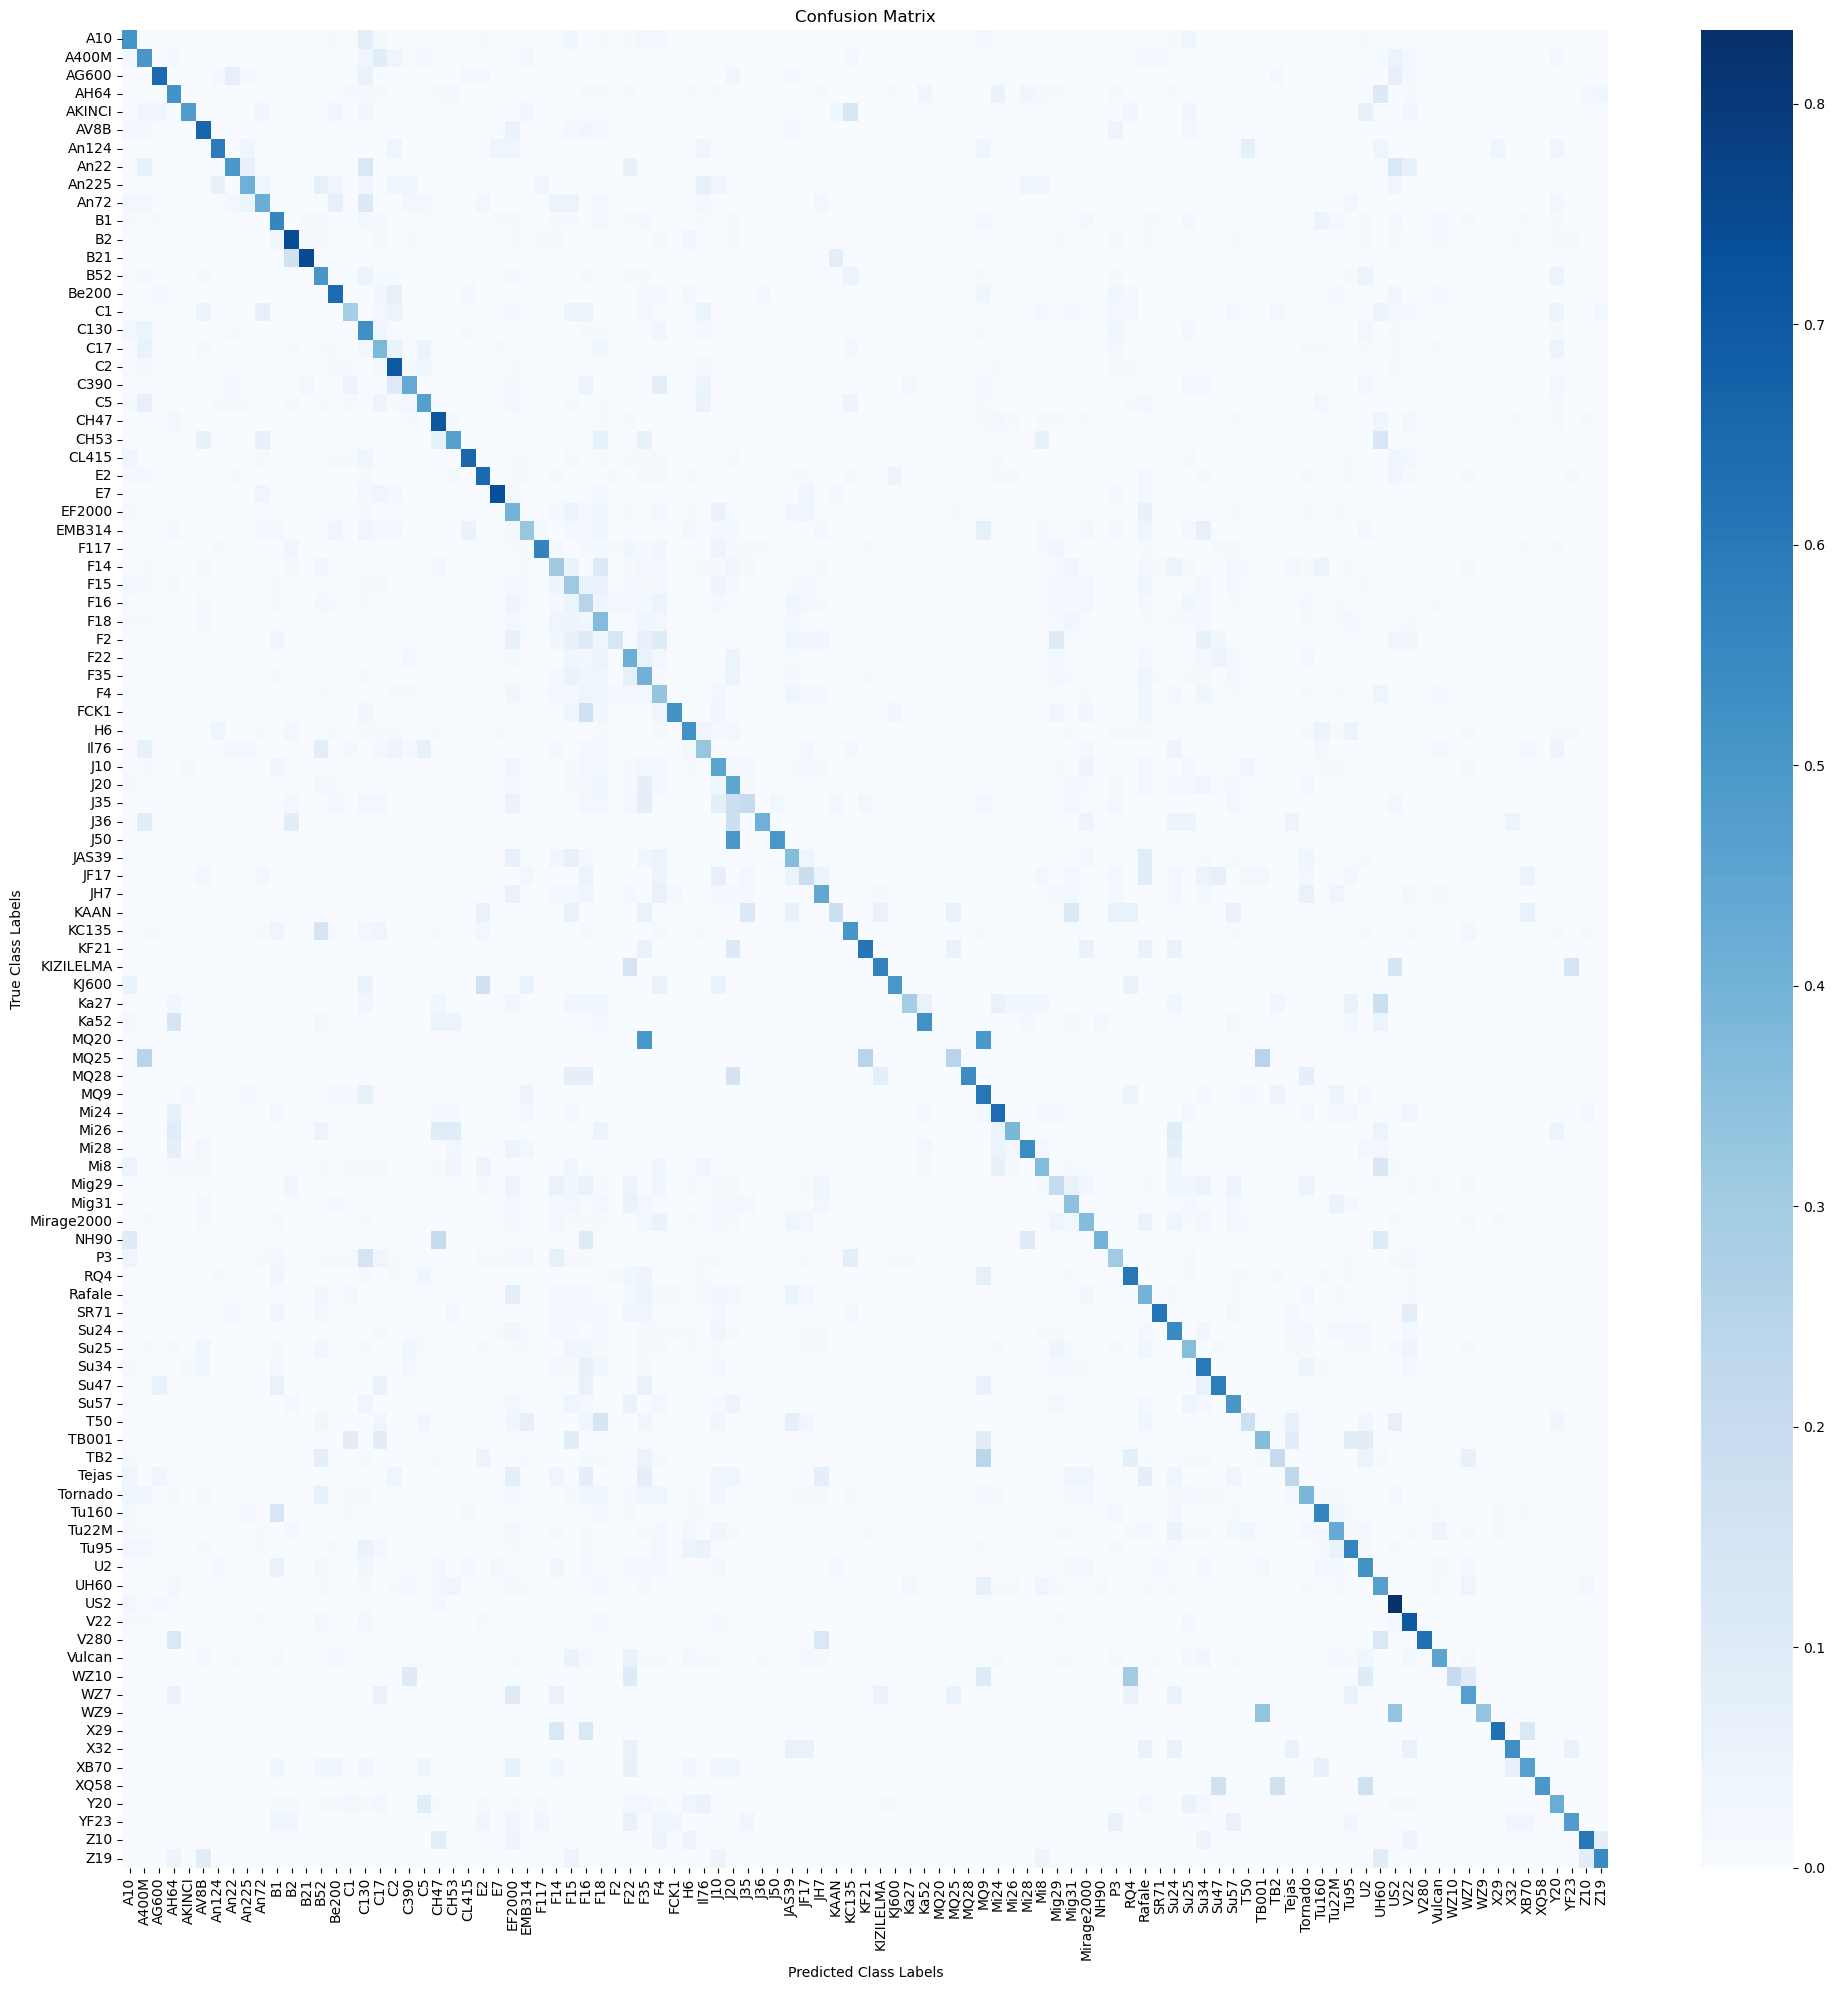

In [149]:
# 1. Build the confusion matrix
cm, cm_norm, class_accuracy = make_confusion_matrix(
    true_label_index=true_label_idxs,
    pred_label_index=pred_label_idxs,
    num_of_classes=len(unique_classes)
)

# 2. Get sorted accuracies
class_accuracy_sorted = get_class_accuracies(
    class_accuracy=class_accuracy,
    class_names=unique_classes
)

# 3. Plot heatmap
plot_confusion_matrix(
    confusion_matrix=cm_norm,
    class_names=unique_classes
)

### **Heatmap Observations**

**Strong diagonal overall**
The model is learning — most classes have at least some correct predictions.
Transfer learning from ImageNet gives the backbone strong general visual features
(edges, textures, shapes) that transfer well to aircraft recognition.

**Fighter jet band (F2, F14, F15, F16, F18, F35) — weak diagonal, scattered confusion**
These aircraft share nearly identical silhouettes — delta wings, twin engines,
similar fuselage profiles. The model sees the same visual features across all of
them and cannot reliably separate them. This is a visual similarity problem,
not a data quantity problem — F16 is the top class by image count yet still
scores only ~25%.

**Drone cluster (MQ20, MQ25, TB2) — near zero accuracy**
Drones are underrepresented in the dataset (bottom classes by image count).
The model has seen very few examples, so it never builds confident drone-specific
features. Combined with similar flat-wing shapes across drone classes, the model
either misclassifies them as other drones or as the nearest visually similar
fixed-wing aircraft.

**Bottom-right cluster (X/Y/Z series) — strongest performance**
These are experimental/unique aircraft with highly distinctive shapes — no other
class looks like them. Visual uniqueness makes them easy to separate. The model
does not have to distinguish between look-alikes, so accuracy is high.

**Several rows nearly blank**
The model has essentially given up on certain classes — it always predicts
something else. This happens when a class is visually ambiguous AND
underrepresented. The model learns to never predict that class because the
penalty for guessing wrong outweighs the rare reward of guessing right.
Class weights partially counteract this but cannot fully fix severe imbalance.

In [150]:
# Find the most confused aircraft pairs

def get_top_confusion_pairs(cm_norm, class_names, n=20):
    """
    Returns the top N most confused class pairs from a normalized confusion matrix.

    Args:
        cm_norm (np.ndarray):
            Row-normalized confusion matrix.
        class_names (list or np.ndarray):
            Class labels corresponding to matrix indices.
        n (int):
            Number of top confusion pairs to return. Default 20.

    Returns:
        list of tuples:
            (true_class, predicted_class, confusion_score)
            Sorted descending by confusion score.
    """
    # Work on a copy — don't modify the original
    matrix_copy = cm_norm.copy()

    # Zero out the diagonal (correct predictions)
    np.fill_diagonal(matrix_copy, 0)

    # Flatten to 1D, get indices sorted by value descending
    flat_indices = np.argsort(matrix_copy.flatten())[::-1][:n]

    # Convert flat indices back to 2D (row, col)
    row_indices, col_indices = np.unravel_index(flat_indices, matrix_copy.shape)

    # Build result
    confusion_pairs = []
    for i, j in zip(row_indices, col_indices):
        confusion_pairs.append((class_names[i], class_names[j], cm_norm[i][j]))

    return confusion_pairs

# n_pairs=len(unique_classes)**2 — that's the total number of off-diagonal cells (101×101 = 10,201).

In [151]:
confusion_pairs = get_top_confusion_pairs(
    cm_norm=cm_norm,
    class_names=unique_classes,
    n=20
)

for true_label, pred_label, score in confusion_pairs:
    print(f"{true_label} → {pred_label}: {score:.2%}")

J50 → J20: 50.00%
MQ20 → F35: 50.00%
MQ20 → MQ9: 50.00%
WZ9 → US2: 33.33%
WZ9 → TB001: 33.33%
WZ10 → RQ4: 30.00%
MQ25 → A400M: 25.00%
MQ25 → TB001: 25.00%
MQ25 → KF21: 25.00%
TB2 → MQ9: 24.19%
NH90 → CH47: 20.00%
J35 → J20: 18.42%
J36 → J20: 18.18%
Ka27 → UH60: 17.65%
FCK1 → F16: 17.24%
B21 → B2: 16.67%
XQ58 → TB2: 16.67%
XQ58 → Su47: 16.67%
XQ58 → U2: 16.67%
KJ600 → E2: 16.67%


### **Top Confusion Pairs Analysis**

| **True Class** | **Predicted As** | **Score** | **Reason** |
|---|---|---|---|
| J50 | J20 | 50% | Same Chinese fighter family, identical silhouette |
| MQ20 | F35 | 50% | Model gave up, defaulted to common fighter jet |
| MQ20 | MQ9 | 50% | Similar drone shape, tiny dataset |
| WZ9 | US2/TB001 | 33% | Model completely lost, essentially guessing |
| WZ10 | RQ4 | 30% | Similar drone/UAV profile |
| MQ25 | A400M/TB001/KF21 | 25% | Drone with too few training images |
| TB2 | MQ9 | 24% | Similar flat-wing drone shape |
| NH90 | CH47 | 20% | Different manufacturers, same rotor+fuselage profile |
| J35/J36 | J20 | 18% | Chinese fighter variants, same family |
| FCK1 | F16 | 17% | South Korean jet heavily inspired by F16 design |
| B21 | B2 | 17% | B21 is next-gen B2 — flying wing, identical silhouette |
| XQ58 | TB2/Su47/U2 | 17% | Unusual stealth drone, no strong match in dataset |
| KJ600 | E2 | 17% | Both carrier-based AEW aircraft, similar disc+fuselage |

**Key takeaway:** Every confusion pair has a real world explanation:
- same aircraft family, similar role, or data scarcity.
- The model is not randomly confused, it is confused in ways that make visual sense.

---

## **16. Fine-Tuning MobileNetV2**

**Objective:**

Push val_accuracy from `46.4%` toward `60–65%` by unfreezing top backbone layers and retraining at very low learning rate.

**What to do:**
- Unfreeze last `~30%` of MobileNetV2 backbone layers
- Keep early layers frozen (edges, gradients — universal, no need to retrain)
- Learning rate: 1e-5 (10x smaller than Phase 1)

**Key Risk:**
- Catastrophic forgetting → high LR destroys pretrained weights. Low LR nudges them.


**Expected Outcome:**

- Epochs 1–3: accuracy may temporarily dip → normal
- Epoch 5+: should climb past 46.4% ceiling
- Hard ceiling for MobileNetV2: ~65%

In [152]:
# How many layers does the baseline model (MobileNetV2) have?
print(f"Total layers:", len(baseline_model.layers))

Total layers: 3


In [153]:
# See all the layers inside the model
for i, layer in enumerate(baseline_model.layers):
    print(f"layer: {i}, name: {layer.name}")
    
# MobileNetV2 backbone (as one block), a pooling layer, and a dense head.

layer: 0, name: mobilenetv2_1.40_224
layer: 1, name: global_average_pooling2d_2
layer: 2, name: dense_2


**The backbone is a nested model. It contains ~154 layers inside it, but from the outside it looks like one single layer.**

In [154]:
# Access the MobileNetV2 backbone, then list its internal layers
basline_backbone = baseline_model.layers[0]

for i, layer in enumerate(basline_backbone.layers):
    print(f"layer: {i:<5}, name: {layer.name}, trainable: {layer.trainable}")
    
# This will show all internal layers + whether each one is currently frozen (trainable: False) or not.

layer: 0    , name: input_layer_4, trainable: True
layer: 1    , name: Conv1, trainable: False
layer: 2    , name: bn_Conv1, trainable: False
layer: 3    , name: Conv1_relu, trainable: False
layer: 4    , name: expanded_conv_depthwise, trainable: False
layer: 5    , name: expanded_conv_depthwise_BN, trainable: False
layer: 6    , name: expanded_conv_depthwise_relu, trainable: False
layer: 7    , name: expanded_conv_project, trainable: False
layer: 8    , name: expanded_conv_project_BN, trainable: False
layer: 9    , name: block_1_expand, trainable: False
layer: 10   , name: block_1_expand_BN, trainable: False
layer: 11   , name: block_1_expand_relu, trainable: False
layer: 12   , name: block_1_pad, trainable: False
layer: 13   , name: block_1_depthwise, trainable: False
layer: 14   , name: block_1_depthwise_BN, trainable: False
layer: 15   , name: block_1_depthwise_relu, trainable: False
layer: 16   , name: block_1_project, trainable: False
layer: 17   , name: block_1_project_BN, train

### **What We Observed**

| | Detail |
|---|---|
| **Total layers** | 154 (index 0–153) |
| **Layer 0** | `input_layer` → trainable but irrelevant, no weights, just passes data in |
| **Layers 1–153** | All frozen (`trainable: False`) from Phase 1 |
| **Unfreeze target** | Layers 107–153 (~30% of backbone) |
| **Starting point** | `block_12_expand` — beginning of block 12 |

---

### **Why block_12?**

MobileNetV2 uses repeating **blocks**. Each block has 3 steps:

```
expand → depthwise → project
```

- **expand**: increases channels (more detail to work with)
- **depthwise**: detects spatial features (shapes at this level)
- **project**: compresses channels back down

Starting at `block_12_expand` means block 12 trains as a complete unit → no block is split mid-way.

---


### **Plan**

From our observation, layers 1-153 are all frozen since training the baseline model.

We need to selectively unfreeze layers 107-153 (`block_12` onwards)
so the backbone can learn aircraft-specific features.

To do this selectively, we can't just unfreeze individual layers directly.
We first unlock the entire backbone, then re-freeze everything below layer 107.

1. Grab the backbone from `baseline_model`
2. Set the entire backbone to `trainable = True` ← unlocks all 154 layers
3. Re-freeze layers 0–106 ← locks early layers back
4. Verify confirm which layers are now trainable

In [155]:
# 1. grab the backbone
baseline_model_backbone = baseline_model.layers[0]

# 2. unlock the entire backbone at once
baseline_model_backbone.trainable = True

In [156]:
# 3. re-freeze early layers (0–106), keep 107–153 trainable
for layer in baseline_model_backbone.layers[:107]:
    layer.trainable = False

In [157]:
# Verifying whether it works
for i, layer in enumerate(baseline_model_backbone.layers):
    print(f"layer: {i:<3}, name: {layer.name:<30}, trainable: {layer.trainable}")

layer: 0  , name: input_layer_4                 , trainable: False
layer: 1  , name: Conv1                         , trainable: False
layer: 2  , name: bn_Conv1                      , trainable: False
layer: 3  , name: Conv1_relu                    , trainable: False
layer: 4  , name: expanded_conv_depthwise       , trainable: False
layer: 5  , name: expanded_conv_depthwise_BN    , trainable: False
layer: 6  , name: expanded_conv_depthwise_relu  , trainable: False
layer: 7  , name: expanded_conv_project         , trainable: False
layer: 8  , name: expanded_conv_project_BN      , trainable: False
layer: 9  , name: block_1_expand                , trainable: False
layer: 10 , name: block_1_expand_BN             , trainable: False
layer: 11 , name: block_1_expand_relu           , trainable: False
layer: 12 , name: block_1_pad                   , trainable: False
layer: 13 , name: block_1_depthwise             , trainable: False
layer: 14 , name: block_1_depthwise_BN          , trainable: F

In [158]:
# Check current optimizer settings on the model
print(baseline_model.optimizer.get_config())

# To check what LR the baseline model ended on (`learning_rate`)
# so we could make an informed decision about what LR to use for fine-tuning.

{'name': 'adam', 'learning_rate': 1.6000001323845936e-06, 'weight_decay': None, 'clipnorm': None, 'global_clipnorm': None, 'clipvalue': None, 'use_ema': False, 'ema_momentum': 0.99, 'ema_overwrite_frequency': None, 'loss_scale_factor': None, 'gradient_accumulation_steps': None, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07, 'amsgrad': False}


### **Recompile the Model**

Changing `trainable` on layers does not automatically update TensorFlow's
training graph, it still thinks the old setup is in place.

We need to recompile to tell TensorFlow: (using `.compile()`)
> "Rebuild the training graph with the updated trainable layers."

**Same model. Same weights. No data lost.**

Only two things change:
- Learning rate → `1e-5`
- TensorFlow now knows which layers to update during backprop

**Why `1e-5`?**

- By end of baseline training, `ReduceLROnPlateau` had decayed the LR down to `1.6e-6`.
- We reset to `1e-5` → slightly higher, but still in the safe range for fine-tuning.
- A high LR would overwrite pretrained backbone weights. `1e-5` nudges them instead.

---

**`.compile() takes:`**

- `optimizer`: what algorithm updates the weights (Adam, SGD, etc) + the learning rate lives here
- `loss`: what function measures how wrong the model is
- `metrics`: what to track during training (accuracy etc)

In [159]:
baseline_model.compile(

    # Multi-class classification loss function
    loss=tf.keras.losses.CategoricalCrossentropy(),

    # Optimizer - 1e-5 to nudge backbone weights, not overwrite them
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),

    metrics=[
        # Exact prediction accuracy
        "accuracy",

        # Checks if correct class exists in top 5 predictions
        tf.keras.metrics.TopKCategoricalAccuracy(
            k=5,
            name="top_5_accuracy"
        )
    ]
)

With the model recompiled, we now kick off fine-tune training.

Same callbacks as baseline 
- EarlyStopping
- ReduceLROnPlateau
- ModelCheckpoint.

**Target:** push val_accuracy from `46.4%` → `60–65%`.

> **Note:** Unlike sklearn where you call `model.fit()` once, deep learning allows you to
> - call `.fit()` multiple times on the same model - each call continues training
> - from where the last one left off. No weights are reset.
> - We call `.fit()` directly on `baseline_model`, not through `train_model()`,
> - because `train_model()` creates a fresh model internally - discarding all baseline weights.

In [160]:
# fine_tune_callbacks = create_callbacks()

# # Training fine-tuned model
# fine_tune_history = baseline_model.fit(
#     x=train_data,
#     epochs=100,
#     validation_data=val_data,
#     initial_epoch=17,
#     callbacks=fine_tune_callbacks
# )
# # .fit() returns a History object (loss, accuracy per epoch)

**Run 1 — Epochs 18–31**
- Kernel crashed at epoch 31
- Best checkpoint saved at epoch 30 → `val_accuracy: 62.45%`
- Resumed from checkpoint

**Observations**
- Val accuracy climbing steadily (45% → 62%)
- Training accuracy at 99% — overfitting expected, EarlyStopping monitoring

| Epoch | Train Acc | Train Top-5 | Val Acc | Val Top-5 | Val Loss | LR |
|---|---|---|---|---|---|---|
| 18 | 50.52% | 79.65% | 45.21% | 72.45% | 2.5501 | 1e-5 |
| 19 | 70.31% | 91.92% | 48.81% | 75.51% | 2.3288 | 1e-5 |
| 20 | 78.98% | 95.50% | 52.11% | 78.13% | 2.1461 | 1e-5 |
| 21 | 85.02% | 97.41% | 55.11% | 79.39% | 2.0590 | 1e-5 |
| 22 | 89.53% | 98.49% | 56.70% | 80.85% | 1.9785 | 1e-5 |
| 23 | 92.34% | 99.18% | 57.15% | 80.85% | 1.9890 | 1e-5 |
| 24 | 94.32% | 99.48% | 58.12% | 81.84% | 1.9542 | 1e-5 |
| 25 | 96.06% | 99.71% | 59.18% | 82.25% | 1.9366 | 1e-5 |
| 26 | 97.09% | 99.82% | 60.11% | 82.78% | 1.9080 | 1e-5 |
| 27 | 97.94% | 99.91% | 60.97% | 83.00% | 1.8979 | 1e-5 |
| 28 | 98.40% | 99.95% | 61.17% | 83.59% | 1.8872 | 1e-5 |
| 29 | 98.87% | 99.96% | 61.44% | 83.90% | 1.8822 | 1e-5 |
| 30 | 99.02% | 99.98% | 62.45% | 84.49% | 1.8531 | 1e-5 |

Best checkpoint: epoch 30 — val_accuracy 62.45%, val_loss 1.8531
Kernel crashed at epoch 31 before completion.

In [161]:
# Load best checkpoint from epoch 30
baseline_model = load_model(
    model_path="../models/mobilenetv2_best_model_2026-05-15_21-28-50_epoch_30.keras"
)

Loading model from: ../models/mobilenetv2_best_model_2026-05-15_21-28-50_epoch_30.keras...
Model loaded successfully.


In [162]:
# Check current optimizer settings on the model
print(baseline_model.optimizer.get_config())

{'name': 'adam', 'learning_rate': 9.999999747378752e-06, 'weight_decay': None, 'clipnorm': None, 'global_clipnorm': None, 'clipvalue': None, 'use_ema': False, 'ema_momentum': 0.99, 'ema_overwrite_frequency': None, 'loss_scale_factor': None, 'gradient_accumulation_steps': None, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07, 'amsgrad': False}


**learning_rate:** 9.999999747378752e-06 → that's **1e-5** (floating point representation). 

**Correct model, correct optimizer.**

In [163]:
# # Fine-tuning resumed from epoch 31 checkpoint
# fine_tune_callbacks = create_callbacks()

# fine_tune_history = baseline_model.fit(
#     x=train_data,
#     epochs=100,
#     validation_data=val_data,
#     initial_epoch=31,
#     callbacks=fine_tune_callbacks
# )

In [164]:
# # Save fine-tuned model
# save_model(baseline_model, "atas_finetuned_mobilenetv2_v1")

| Epoch | Train Loss | Train Acc | Train Top-5 | Val Loss | Val Acc | Val Top-5 | LR |
|---|---|---|---|---|---|---|---|
| 32 | 0.0475 | 99.29% | 99.98% | 1.8631 | 62.78% | 84.81% | 1e-5 |
| 33 | 0.0425 | 99.31% | 99.99% | 1.8740 | 62.84% | 84.24% | 1e-5 |
| 34 | 0.0356 | 99.50% | 100.00% | 1.8637 | 63.09% | 84.35% | 1e-5 |
| 35 | 0.0272 | 99.67% | 100.00% | 1.8254 | 63.78% | 84.73% | 2e-6 |
| 36 | 0.0244 | 99.73% | 100.00% | 1.8215 | 64.03% | 84.86% | 2e-6 |
| 37 | 0.0212 | 99.84% | 100.00% | 1.8165 | 64.00% | 85.09% | 2e-6 |
| 38 | 0.0204 | 99.80% | 100.00% | 1.8045 | 64.06% | 85.13% | 2e-6 |
| 39 | 0.0193 | 99.81% | 100.00% | 1.8117 | 64.35% | 85.10% | 2e-6 |
| 40 | 0.0188 | 99.82% | 100.00% | 1.8168 | 64.44% | 85.02% | 2e-6 |
| 41 | 0.0169 | 99.87% | 100.00% | 1.8210 | 64.31% | 84.94% | 4e-7 |
| 42 | 0.0164 | 99.86% | 100.00% | 1.8176 | 64.43% | 84.97% | 4e-7 |
| 43 | 0.0167 | 99.86% | 100.00% | 1.8144 | 64.56% | 85.00% | 1e-7 |

### F**ine-Tuning Observations**

- Val accuracy climbed steadily: 45.2% → 64.56% over 43 epochs
- ReduceLROnPlateau triggered twice: `1e-5 → 2e-6 → 4e-7`
- Overfitting present → train accuracy ~99.8% vs val ~64.5%
- MobileNetV2 ceiling reached (~65%)
- Model trained and saved successfully

**Next:** Make predictions on val set → confusion matrix → compare against baseline predictions → new notebook with EfficientNetV2 backbone, target 70–80%+

---

## **17. Making Predictions Using Fine-Tuned Model**

With fine-tuning complete, we now evaluate the fine-tuned model on the validation set.

The goal is to compare these predictions against the baseline, to see how much fine-tuning actually moved the needle across individual classes.

**Steps:**
1. Reload the fine-tuned model from disk
2. Run predictions on the full validation set
3. Save predictions to CSV
4. Compare against baseline predictions via confusion matrix

In [165]:
# Loading the saved fine-tune model
fine_tune_model = load_model("../release_models/atas_finetuned_mobilenetv2_v1_2026-05-16_05-29-17.keras")

Loading model from: ../release_models/atas_finetuned_mobilenetv2_v1_2026-05-16_05-29-17.keras...
Model loaded successfully.


In [166]:
val_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 101), dtype=tf.int64, name=None))>

In [167]:
# # Make prediction using fine-tune model
# fine_tune_predictions = make_predictions(model=fine_tune_model,
#                                          data_batches=val_data,
#                                          verbose=1)

In [168]:
# # Saving the fine tune predictions to CSV
# save_predictions(predictions=fine_tune_predictions,
#                  file_suffix="fine_tuned")

### **17.1 Evaluating Fine-Tuned Predictions**

Fine-tuned predictions are loaded. We can plug them directly into the evaluation pipeline built earlier.

**Functions we'll use:**
- `plot_predictions_comparison()` → same image, baseline vs fine-tuned side by side
  
- `make_confusion_matrix()` + `plot_confusion_matrix()` → class-wise prediction breakdown
  
- `get_class_accuracies()` → spot strongest and weakest classes
  
- `get_top_confusion_pairs()` → find the most confused aircraft pairs

In [171]:
# Load the fine-tuned predictions
fine_tuned_predictions = load_predictions("../predictions/fine_tuned_predictions_20260516_055636.csv")

Loading predictions from CSV file...
Predictions loaded successfully.


In [172]:
# Load baseline predictions
baseline_predictions = load_predictions("../predictions/mobilenetv2_full_predictions_20260514_191545.csv")

Loading predictions from CSV file...
Predictions loaded successfully.


### **Baseline vs Fine-Tuned: Comparison**

Both prediction sets loaded to compare model performance directly.
Fine-tuning changes internal weights, so loading both lets us see exactly
which classes improved, which regressed, and whether accuracy gains
were uniform or concentrated.

- **Baseline** → MobileNetV2, head-only training (val acc: 46.4%)
- **Fine-Tuned** → Layers 107–153 unfrozen (val acc: 64.56%)

Plan:
1. Visualize sample predictions from both models
2. Plot confusion matrices side by side
3. Compare per-class accuracies

In [175]:
def plot_predictions_comparison(prediction_probabilities_baseline,
                                prediction_probabilities_fine_tuned,
                                true_labels,
                                images,
                                n=1):
    """
    Plot the same image twice — baseline prediction on the left,
    fine-tuned prediction on the right.

    Title color:
    - Blue  → correct prediction
    - Coral → incorrect prediction

    Args:
        prediction_probabilities_baseline (np.ndarray):
            Prediction probabilities from the baseline model (N, num_classes)

        prediction_probabilities_fine_tuned (np.ndarray):
            Prediction probabilities from the fine-tuned model (N, num_classes)

        true_labels (list):
            List of true class labels

        images (list):
            List of image filepaths or processed image arrays

        n (int):
            Index of the sample to visualize
    """

    # Get probabilities, true label, and image for sample n
    baseline_probs = prediction_probabilities_baseline[n]
    fine_tuned_probs = prediction_probabilities_fine_tuned[n]
    true_label = true_labels[n]
    image = images[n]

    # Process image only if input is a filepath
    if isinstance(image, str):
        image = process_image(image)

    # Convert tensor to numpy array if needed
    if tf.is_tensor(image):
        image = image.numpy()

    # Get predicted labels
    baseline_pred_label = get_pred_label(baseline_probs)  # unique_classes[np.argmax(any_prediction_probabilities)]

    fine_tuned_pred_label = get_pred_label(fine_tuned_probs)

    # Each model gets its own colour independently
    baseline_colour = "blue" if baseline_pred_label == true_label else "coral"
    fine_tuned_colour = "blue" if fine_tuned_pred_label == true_label else "coral"

    # Make figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # Plot baseline prediction
    ax1.imshow(image)
    ax1.axis("off")
    ax1.set_title(f"Baseline\n{baseline_pred_label} | {np.max(baseline_probs)*100:.2f}% | True: {true_label}",
                  color=baseline_colour)

    # Plot fine-tuned prediction
    ax2.imshow(image)
    ax2.axis("off")
    ax2.set_title(f"Fine-Tuned\n{fine_tuned_pred_label} | {np.max(fine_tuned_probs)*100:.2f}% | True: {true_label}",
                  color=fine_tuned_colour)

In [ ]:
# Loading validation images and labels
val_images, val_labels = X_val, y_val

len(val_images), len(val_labels), basline_predictions.shape, fine_tuned_predictions.shape

(7545, 7545, (7545, 101), (7545, 101))

In [180]:
val_images[:2]

<StringArray>
['../data/crop/A10/c00aa3e8b7fe8ddcaee8b927c0aee8c2_0.jpg', '../data/crop/A10/c013d8c11f35868538e7ef4207fe35e2_0.jpg']
Length: 2, dtype: str

In [182]:
# Getting the true labels
true_labels = unique_classes[np.argmax(val_labels, axis=1)]
true_labels[:2]

array(['A10', 'A10'], dtype='<U10')

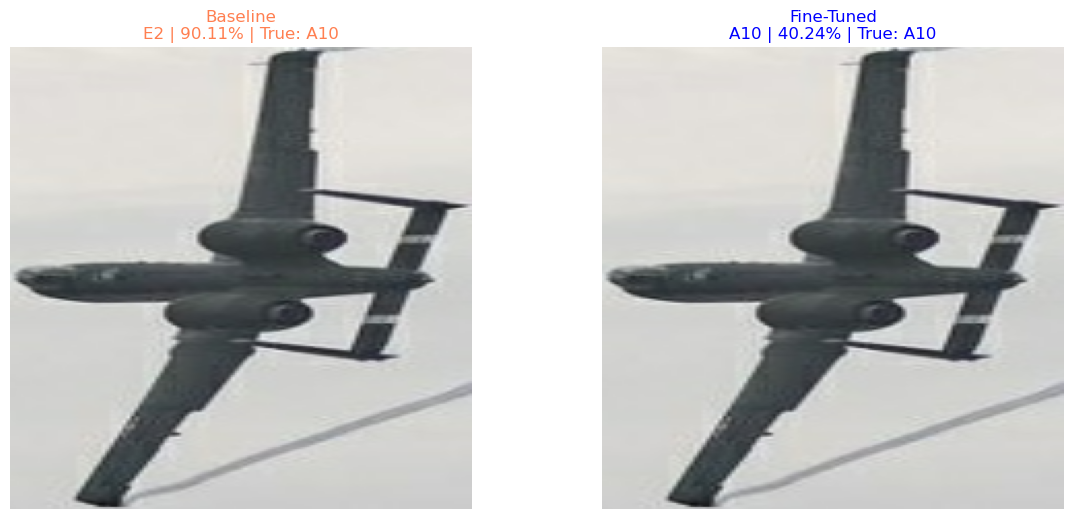

In [183]:
# Visualizing the same image twice usimg baseline and fine-tuned predictions
plot_predictions_comparison(prediction_probabilities_baseline=basline_predictions,
                            prediction_probabilities_fine_tuned=fine_tuned_predictions,
                            true_labels=true_labels,
                            images=val_images,
                            n=0)

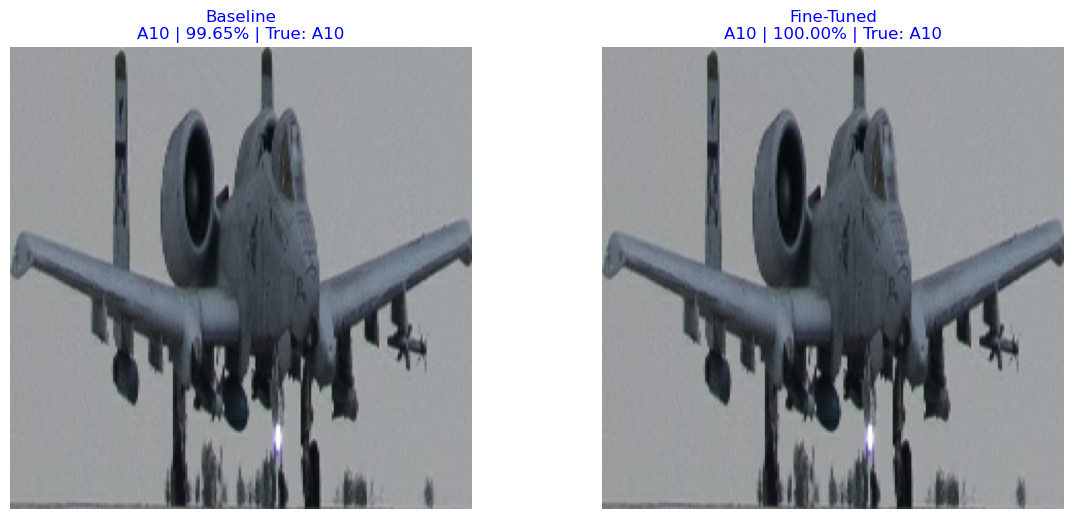

In [184]:
plot_predictions_comparison(prediction_probabilities_baseline=basline_predictions,
                            prediction_probabilities_fine_tuned=fine_tuned_predictions,
                            true_labels=true_labels,
                            images=val_images,
                            n=5)

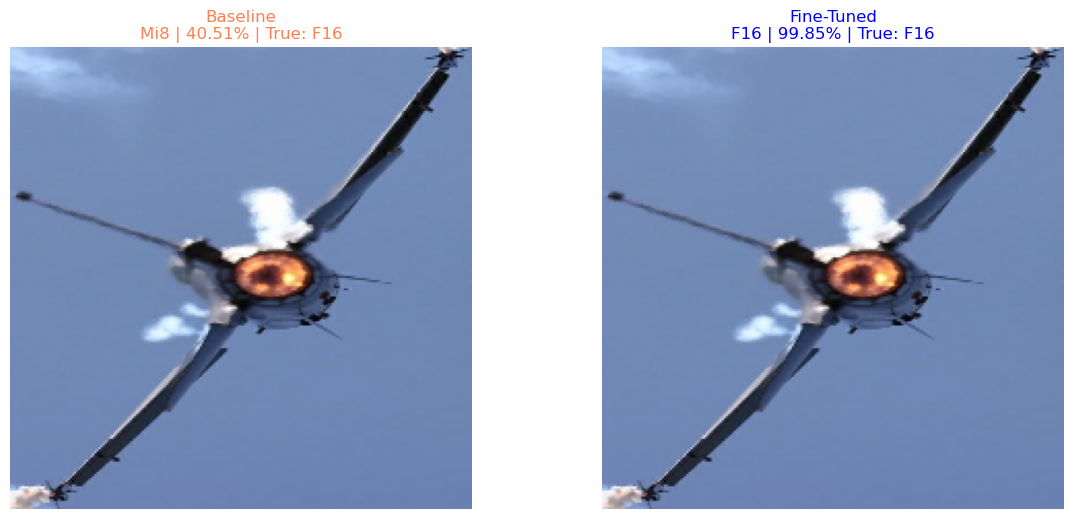

In [189]:
plot_predictions_comparison(prediction_probabilities_baseline=basline_predictions,
                            prediction_probabilities_fine_tuned=fine_tuned_predictions,
                            true_labels=true_labels,
                            images=val_images,
                            n=3000)

### **Confusion Matrix - Baseline vs Fine-Tuned**

Sample predictions show clear improvement — fine-tuned correctly identifies
aircraft that baseline misclassifies entirely (e.g. F16 predicted as MI8).
Confidence is also higher on correct predictions.

Some errors remain, expected given MobileNetV2's practical ceiling at this
dataset size and class imbalance.

Next: plot confusion matrices for both models to see class-level breakdown.

In [192]:
# Convert one-hot encoded arrays -> class index integers
# val_labels shape: (7545, 101) → (7545,)
# # baseline_predictions shape: (7545, 101) → (7545,)
# # fine_tuned_predictions shape: (7545, 101) → (7545,)

true_label_idxs = np.argmax(val_labels, axis=1)
baseline_pred_label_idxs = np.argmax(basline_predictions, axis=1)
fine_tuned_pred_label_idxs = np.argmax(fine_tuned_predictions, axis=1)
# name_of_classes -> unique_classes

In [ ]:
# Make confusion matrix from baseline predictions
baseline_cm, baseline_cm_norm, baseline_class_accuracy = make_confusion_matrix(
    true_label_index=true_label_idxs,
    pred_label_index=baseline_pred_label_idxs,
    num_of_classes=len(unique_classes)
)

In [196]:
# Make confusion matrix from fine-tuned predictions
fine_tuned_cm, fine_tuned_cm_norm, fine_tuned_class_accuracy = make_confusion_matrix(
    true_label_index=true_label_idxs,
    pred_label_index=fine_tuned_pred_label_idxs,
    num_of_classes=len(unique_classes)
)

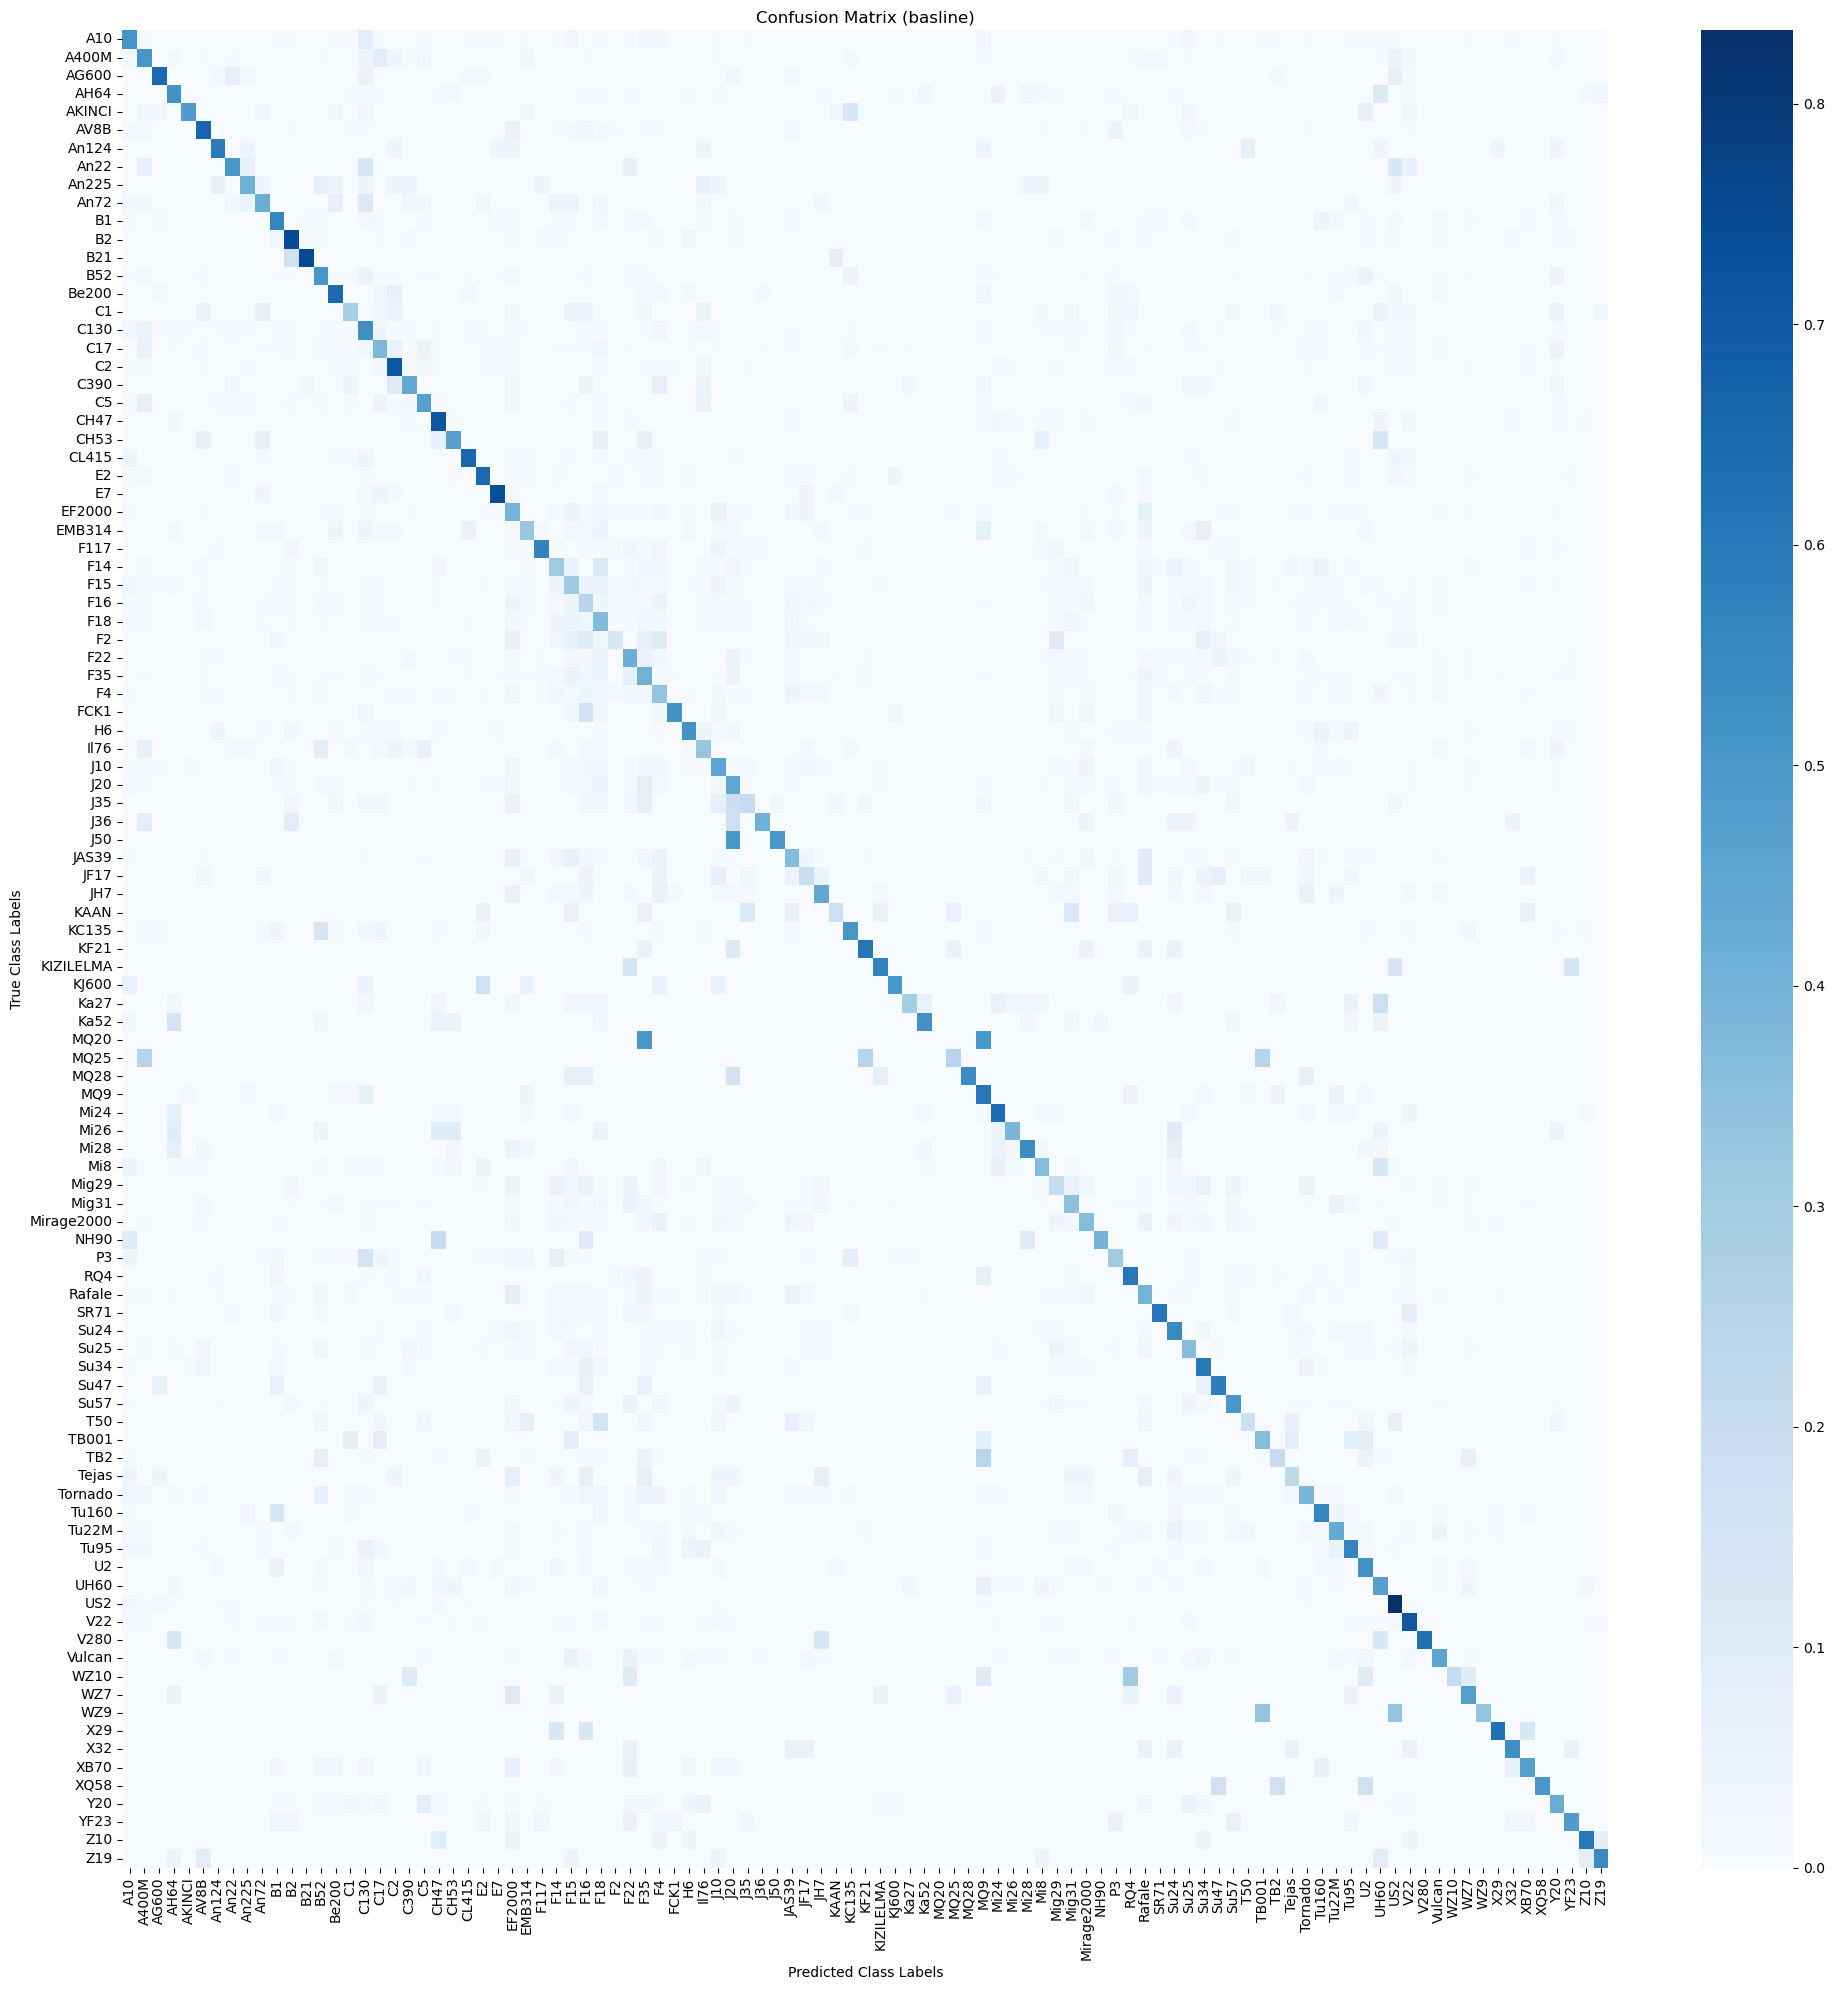

In [198]:
# Plotting confusion matrix from Baseline predictions
plot_confusion_matrix(confusion_matrix=baseline_cm_norm,
                      class_names=unique_classes,
                      title="Confusion Matrix (basline)")

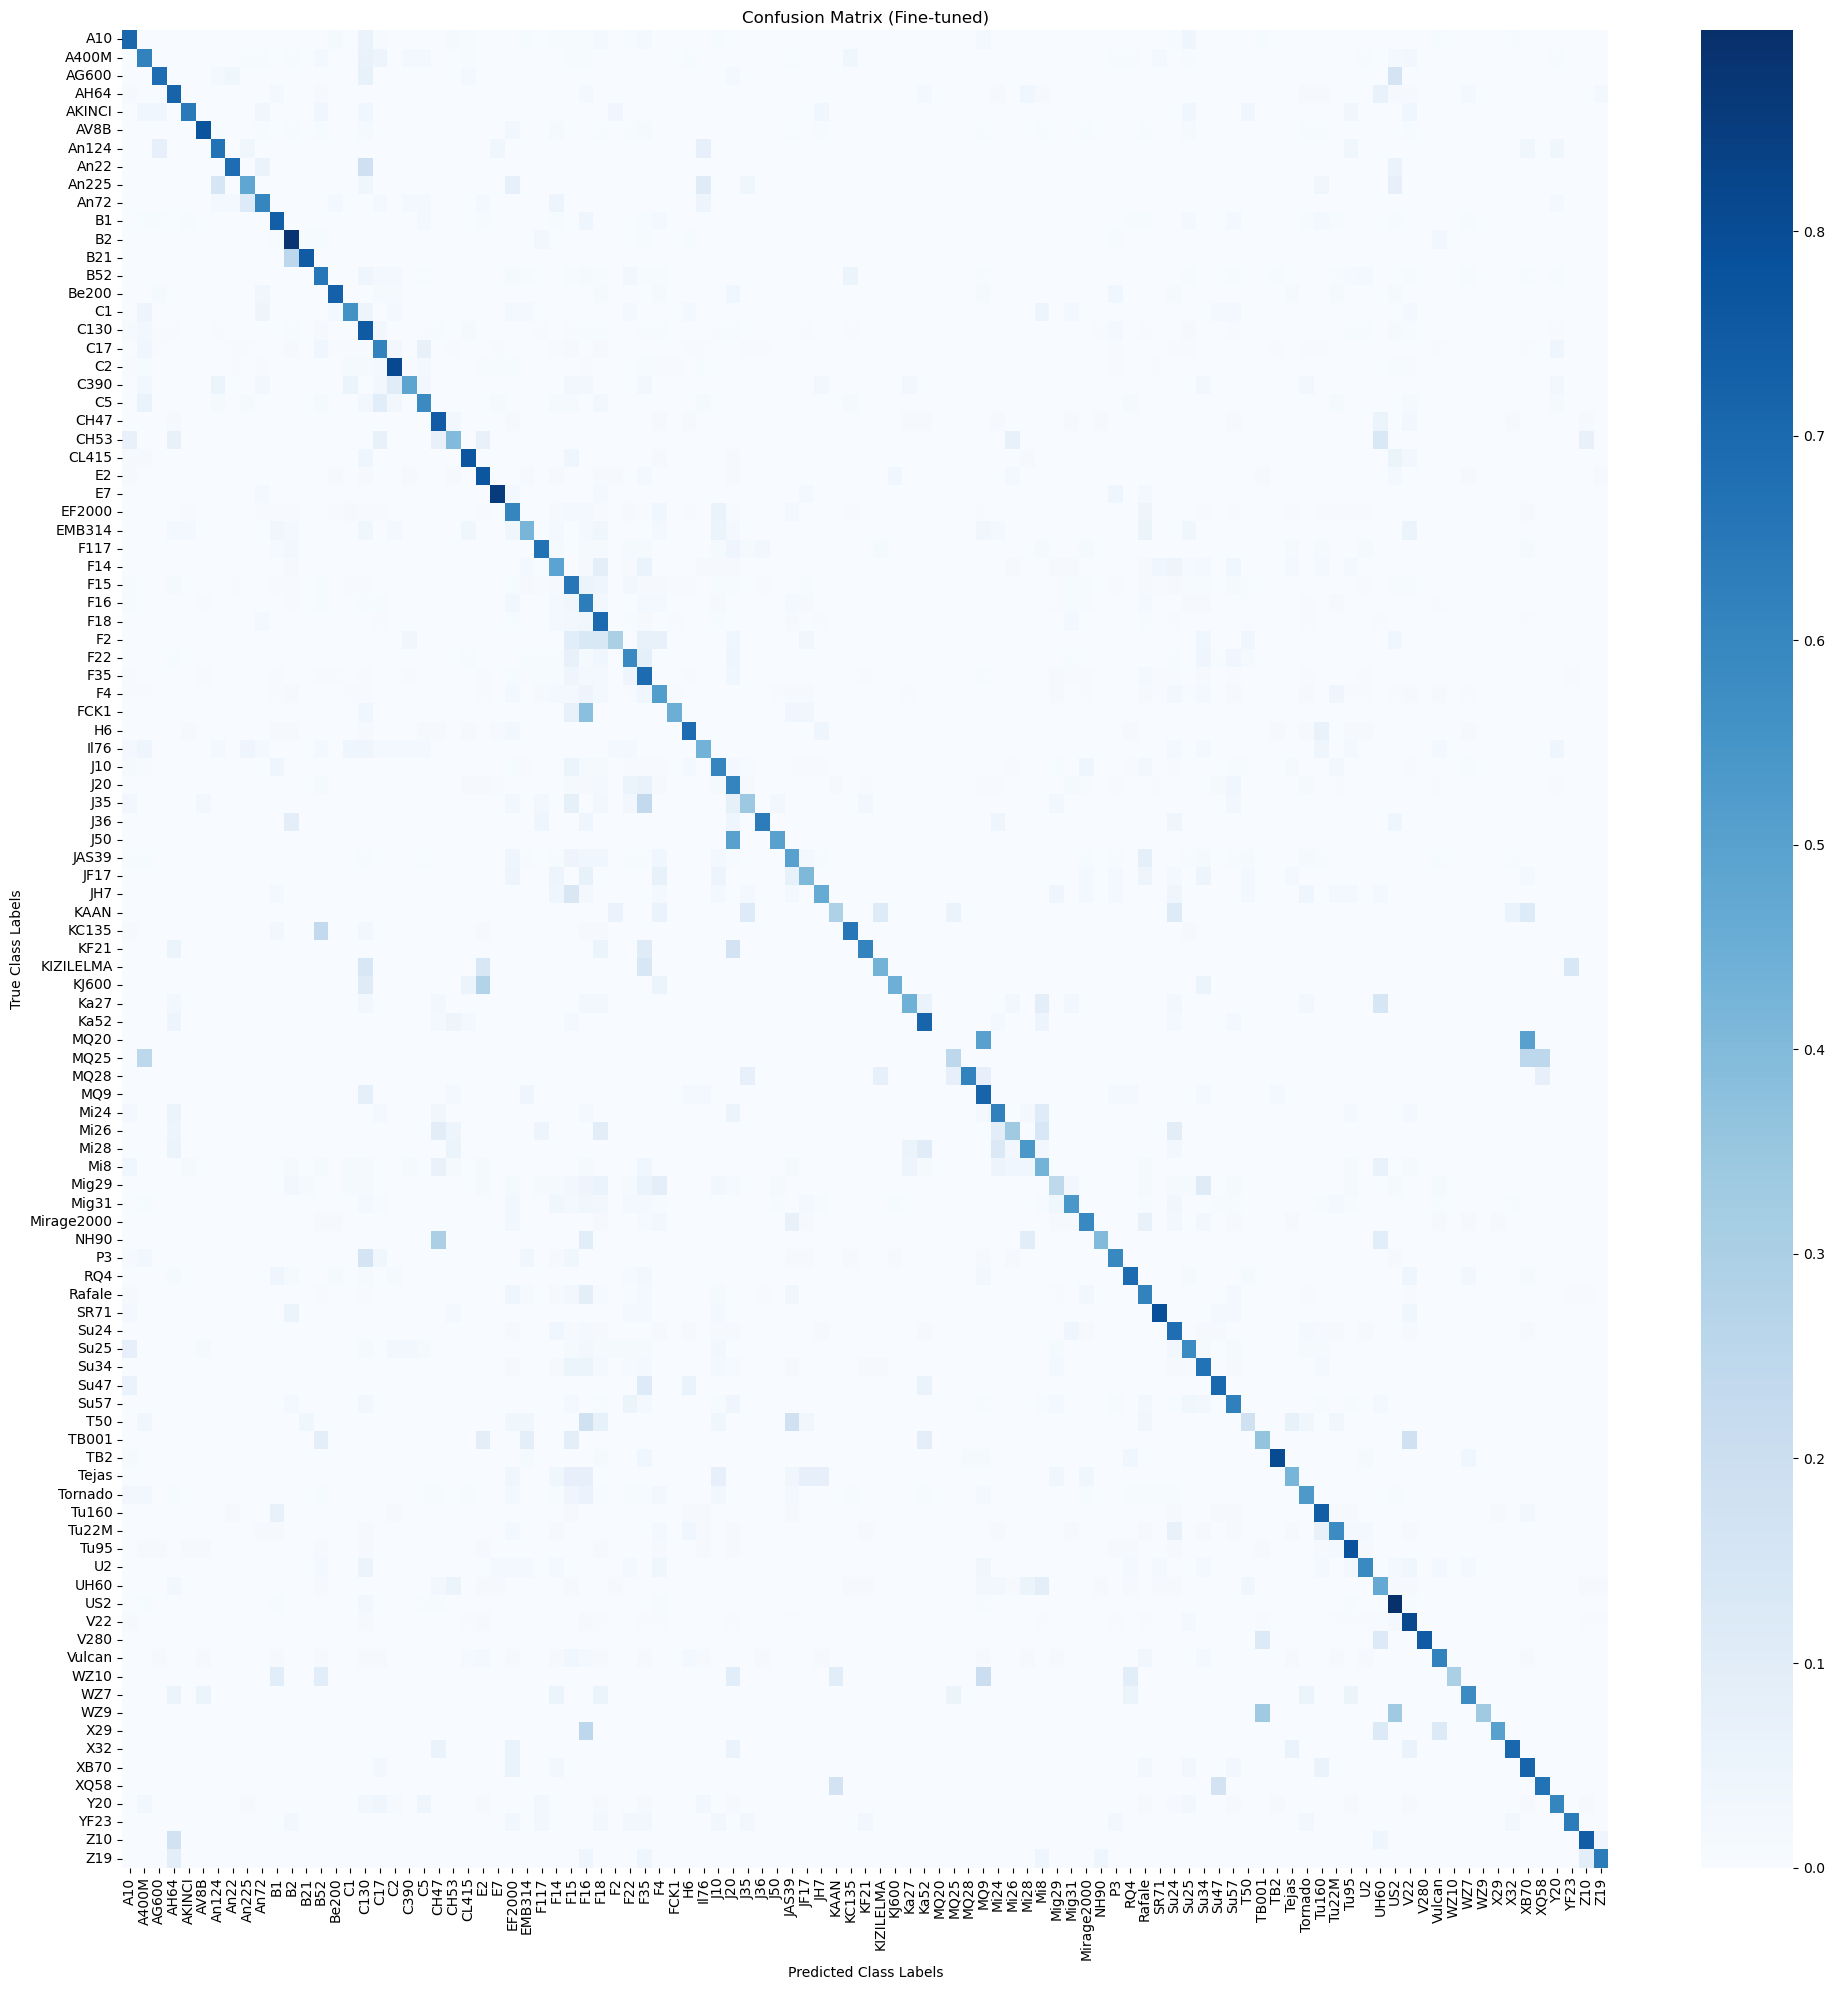

In [199]:
# Plotting Confusion matrix from Fine-tuned predictions
plot_confusion_matrix(confusion_matrix=fine_tuned_cm_norm,
                      class_names=unique_classes,
                      title="Confusion Matrix (Fine-tuned)")

### **Confusion Matrix Analysis**

Baseline → Fine-Tuned improvement is not just numerical — the error structure changed qualitatively.

**Baseline:** random fallback behavior, weak diagonals, frequent cross-family errors

**Fine-Tuned:** semantically coherent confusion, errors concentrated within aircraft families

Key findings:
- Fighter families (F15/F16/F18/F35) sharpened significantly
- J20-cluster improved but stealth geometry overlaps by design
- UAV subclasses (MQ20, WZ9, WZ10) still collapse — data scarcity, not model failure
- B2/B21 confusion is fundamentally unsolvable at 224×224

MobileNetV2 ceiling confirmed. At 224×224 tail geometry, intake shape, and cockpit
details compress, fine-grained discrimination breaks down.

**Next:** EfficientNetV2-L at 480×480 with augmentation and class balancing targets
exactly what MobileNetV2 cannot fix architecturally.

In [201]:
# Baseline model class accuracies
baseline_class_accuracy = get_class_accuracies(class_accuracy=baseline_class_accuracy,
                                                      class_names=unique_classes)

In [202]:
# Fine-tuned class accuracies
fine_tuned_class_accuracy = get_class_accuracies(class_accuracy=fine_tuned_class_accuracy,
                                                 class_names=unique_classes)

In [203]:
# Bottom 5 accuracies
print("Baseline -> worst 5:")
for class_name, acc in baseline_class_accuracy[:5]:
    print(f"{class_name}: {acc:.2%}")
    
print("\nFine-Tuned -> worst 5")
for class_name, acc in fine_tuned_class_accuracy[:5]:
    print(f"{class_name}: {acc:.2%}")

Baseline -> worst 5:
MQ20: 0.00%
F2: 13.33%
KAAN: 17.65%
T50: 17.86%
JF17: 19.05%

Fine-Tuned -> worst 5
MQ20: 0.00%
T50: 17.86%
Mig29: 24.62%
MQ25: 25.00%
KAAN: 29.41%


In [204]:
# Top 5 accuracies
print("Baseline -> best 5:")
for class_name, acc in baseline_class_accuracy[-5:]:
    print(f"{class_name}: {acc:.2%}")
    
print("\nFine-Tuned -> best 5")
for class_name, acc in fine_tuned_class_accuracy[-5:]:
    print(f"{class_name}: {acc:.2%}")

Baseline -> best 5:
CH47: 70.89%
E7: 73.47%
B2: 74.26%
B21: 75.00%
US2: 83.33%

Fine-Tuned -> best 5
C2: 81.41%
V22: 81.71%
E7: 85.71%
B2: 88.12%
US2: 89.81%


### **Per-Class Accuracy Analysis**

**Worst performers (both models):**
- MQ20: 0.00% → 11 training images, unfixable without more data
- Fine-tuning did not universally improve every class → Mig29 dropped into
  worst 5 after fine-tuning, indicating some classes regressed slightly

**Best performers:**
- Distinctive silhouettes (US2, B2, E7) improved significantly
- US2: 83.33% → 89.81% | B2: 74.26% → 88.12% | E7: 73.47% → 85.71%

**Conclusion:** Fine-tuning gains are real but uneven. Classes with sufficient
data and distinctive geometry improved strongly. Data-scarce classes remain
broken regardless of fine-tuning → a data problem, not a model problem.

`MobileNetV2` v1 is complete. 

**Next:**

`EfficientNetV2-L` at **480×480** with class
balancing and augmentation in `02_aircraft_classifier_v2.ipynb`.

---